In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

print("Project exists:", os.path.exists(PROJECT_DIR))

Project exists: False


In [2]:
# RESUME 02 - CLEAN TENSORFLOW START

import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TF_XLA_FLAGS"] = "--tf_xla_auto_jit=0"

import tensorflow as tf

tf.config.optimizer.set_jit(False)

print("✅ TensorFlow ready")
print("GPU:", tf.config.list_physical_devices("GPU"))

✅ TensorFlow ready
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [9]:
# CODE 01A - PROJECT SETUP

import os
import json

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

folders = ["data", "models", "reports", "outputs"]

for folder in folders:
    os.makedirs(
        os.path.join(PROJECT_DIR, folder),
        exist_ok=True
    )

config = {
    "classes": ["BCC", "MCC", "Melanoma", "SCC"],
    "image_size": 299
}

with open(
    os.path.join(PROJECT_DIR, "config.json"),
    "w"
) as f:
    json.dump(config, f, indent=4)

print("✅ Project setup saved")
print(PROJECT_DIR)

✅ Project setup saved
/kaggle/working/skin_cancer_project_v2


In [10]:
# CODE 01B - CHECK EXACT DATASET PATHS

import os

BASE_PATH = "/kaggle/input/datasets"

for root, dirs, files in os.walk(BASE_PATH):
    if root.count(os.sep) == BASE_PATH.count(os.sep) + 2:
        print(root)

/kaggle/input/datasets/tomooinubushi/all-isic-data-20240629
/kaggle/input/datasets/nodoubttome/skin-cancer9-classesisic
/kaggle/input/datasets/riyaelizashaju/isic-skin-disease-image-dataset-labelled
/kaggle/input/datasets/ahmedxc4/skin-ds
/kaggle/input/datasets/quantumcoders04/skin-cancer-final-integration
/kaggle/input/datasets/quantumcoders04/merkel-cell-carsinoma-2
/kaggle/input/datasets/quantumcoders04/scc-dataset
/kaggle/input/datasets/quantumcoders04/merkel-cell-carsinoma-3
/kaggle/input/datasets/quantumcoders04/merkel-cell-carsinoma-1
/kaggle/input/datasets/quantumcoders04/merkel-cell-carsinoma-4
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000
/kaggle/input/datasets/hiro002/dermacon-in-dataset


In [11]:
# CODE 01C - SAVE EXACT DATASET PATHS

import os
import json

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"
os.makedirs(PROJECT_DIR, exist_ok=True)

DATASET_PATHS = [
    "/kaggle/input/datasets/riyaelizashaju/isic-skin-disease-image-dataset-labelled",
    "/kaggle/input/datasets/nodoubttome/skin-cancer9-classesisic",
    "/kaggle/input/datasets/tomooinubushi/all-isic-data-20240629",
    "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000",
    "/kaggle/input/datasets/quantumcoders04/merkel-cell-carsinoma-1",
    "/kaggle/input/datasets/quantumcoders04/merkel-cell-carsinoma-4",
    "/kaggle/input/datasets/quantumcoders04/scc-dataset",
    "/kaggle/input/datasets/quantumcoders04/merkel-cell-carsinoma-2",
    "/kaggle/input/datasets/quantumcoders04/merkel-cell-carsinoma-3",
    "/kaggle/input/datasets/hiro002/dermacon-in-dataset",
    "/kaggle/input/datasets/ahmedxc4/skin-ds"
]

save_path = os.path.join(PROJECT_DIR, "dataset_paths.json")

with open(save_path, "w") as f:
    json.dump(DATASET_PATHS, f, indent=4)

print("✅ Exact dataset paths saved")
print("Total datasets:", len(DATASET_PATHS))
print(save_path)

✅ Exact dataset paths saved
Total datasets: 11
/kaggle/working/skin_cancer_project_v2/dataset_paths.json


In [12]:
# CODE 02A - COUNT IMAGES IN EACH DATASET

import os
import json
import pandas as pd

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

with open(
    os.path.join(PROJECT_DIR, "dataset_paths.json"),
    "r"
) as f:
    DATASET_PATHS = json.load(f)

IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")

results = []

for path in DATASET_PATHS:

    count = 0

    for root, dirs, files in os.walk(path):
        count += sum(
            file.lower().endswith(IMAGE_EXTS)
            for file in files
        )

    results.append({
        "dataset": os.path.basename(path),
        "image_count": count
    })

df_counts = pd.DataFrame(results)

save_path = os.path.join(
    PROJECT_DIR,
    "data",
    "dataset_image_counts.csv"
)

os.makedirs(
    os.path.dirname(save_path),
    exist_ok=True
)

df_counts.to_csv(
    save_path,
    index=False
)

display(df_counts)

print("\n✅ Dataset image counts saved")
print(save_path)

,dataset,image_count
0,isic-skin-disease-image-dataset-labelled,25331
1,skin-cancer9-classesisic,4714
2,all-isic-data-20240629,81722
3,skin-cancer-mnist-ham10000,20030
4,merkel-cell-carsinoma-1,17
5,merkel-cell-carsinoma-4,12
6,scc-dataset,12
7,merkel-cell-carsinoma-2,10
8,merkel-cell-carsinoma-3,20
9,dermacon-in-dataset,5450



✅ Dataset image counts saved
/kaggle/working/skin_cancer_project_v2/data/dataset_image_counts.csv


In [14]:
# CODE 02B - SAVE RAW IMAGE MANIFEST

import os
import json
import pandas as pd

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

with open(PROJECT_DIR + "/dataset_paths.json") as f:
    DATASET_PATHS = json.load(f)

IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")

rows = []

for dataset_path in DATASET_PATHS:
    for root, _, files in os.walk(dataset_path):
        for file in files:
            if file.lower().endswith(IMAGE_EXTS):
                rows.append({
                    "dataset": os.path.basename(dataset_path),
                    "image_path": os.path.join(root, file)
                })

df = pd.DataFrame(rows)

save_path = PROJECT_DIR + "/data/raw_image_manifest.csv"
df.to_csv(save_path, index=False)

print("✅ Raw image manifest saved")
print("Total images:", len(df))
print(save_path)

✅ Raw image manifest saved
Total images: 173974
/kaggle/working/skin_cancer_project_v2/data/raw_image_manifest.csv


In [42]:
# CODE 03A - VALIDATE NEXT 5000 IMAGES

import os
import pandas as pd
from PIL import Image

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

raw_path = PROJECT_DIR + "/data/raw_image_manifest.csv"
save_path = PROJECT_DIR + "/data/image_validation.csv"

df = pd.read_csv(raw_path)

# Load previous progress
if os.path.exists(save_path):
    done = pd.read_csv(save_path)
    processed = set(done["image_path"])
else:
    done = pd.DataFrame()
    processed = set()

# Get only next 5000 unprocessed images
batch = df[
    ~df["image_path"].isin(processed)
].head(5000)

results = []

for path in batch["image_path"]:

    try:
        with Image.open(path) as img:
            width, height = img.size

        results.append([
            path, True, width, height
        ])

    except:
        results.append([
            path, False, 0, 0
        ])

new_df = pd.DataFrame(
    results,
    columns=[
        "image_path",
        "valid",
        "width",
        "height"
    ]
)

# Append and save
done = pd.concat(
    [done, new_df],
    ignore_index=True
)

done.to_csv(
    save_path,
    index=False
)

print("✅ This batch:", len(new_df))
print("✅ Total completed:", len(done))
print("⏳ Remaining:", len(df) - len(done))

✅ This batch: 3974
✅ Total completed: 173974
⏳ Remaining: 0


In [43]:
# CODE 03B - CONTINUE VALIDATION SAFELY

import os
import pandas as pd
from PIL import Image

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

raw_path = PROJECT_DIR + "/data/raw_image_manifest.csv"
save_path = PROJECT_DIR + "/data/image_validation.csv"

raw_df = pd.read_csv(raw_path)

if os.path.exists(save_path):
    done_df = pd.read_csv(save_path)
else:
    done_df = pd.DataFrame(
        columns=["image_path", "valid", "width", "height"]
    )

processed = set(done_df["image_path"])

batch = raw_df[
    ~raw_df["image_path"].isin(processed)
].head(10000)

results = []

for i, path in enumerate(batch["image_path"], start=1):

    try:
        with Image.open(path) as img:
            width, height = img.size

        results.append([path, True, width, height])

    except:
        results.append([path, False, 0, 0])

    # Save every 1000 images
    if i % 1000 == 0:

        temp = pd.DataFrame(
            results,
            columns=["image_path", "valid", "width", "height"]
        )

        done_df = pd.concat(
            [done_df, temp],
            ignore_index=True
        )

        done_df.to_csv(save_path, index=False)

        results = []

        print("✅ Saved progress:", len(done_df))


# Save remaining images
if results:

    temp = pd.DataFrame(
        results,
        columns=["image_path", "valid", "width", "height"]
    )

    done_df = pd.concat(
        [done_df, temp],
        ignore_index=True
    )

    done_df.to_csv(save_path, index=False)


print("\n✅ Total validated:", len(done_df))
print("⏳ Remaining:", len(raw_df) - len(done_df))


✅ Total validated: 173974
⏳ Remaining: 0


In [44]:
# CODE 03C - CREATE CLEAN VALID IMAGE MANIFEST

import pandas as pd

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

raw = pd.read_csv(
    PROJECT_DIR + "/data/raw_image_manifest.csv"
)

val = pd.read_csv(
    PROJECT_DIR + "/data/image_validation.csv"
)

df = raw.merge(
    val,
    on="image_path",
    how="left"
)

# Very small image = width or height below 100 pixels
df["small_image"] = (
    (df["width"] < 100) |
    (df["height"] < 100)
)

clean_df = df[
    (df["valid"] == True) &
    (df["small_image"] == False)
].copy()

# Save both full checked manifest and clean manifest
df.to_csv(
    PROJECT_DIR + "/data/validated_manifest.csv",
    index=False
)

clean_df.to_csv(
    PROJECT_DIR + "/data/clean_valid_manifest.csv",
    index=False
)

print("Total images :", len(df))
print("Invalid      :", (~df["valid"]).sum())
print("Small <100px :", df["small_image"].sum())
print("Clean images :", len(clean_df))

print("\n✅ Clean manifest saved")

Total images : 173974
Invalid      : 0
Small <100px : 47
Clean images : 173927

✅ Clean manifest saved


In [45]:
# CODE 04A - CHECK TARGET CLASS FOLDERS

import os
import pandas as pd

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

df = pd.read_csv(
    PROJECT_DIR + "/data/clean_valid_manifest.csv"
)

df["parent_folder"] = df["image_path"].apply(
    lambda x: os.path.basename(os.path.dirname(x))
)

keywords = [
    "bcc",
    "basal",
    "mcc",
    "merkel",
    "melanoma",
    "mel",
    "scc",
    "squamous"
]

mask = df["image_path"].str.lower().apply(
    lambda x: any(k in x for k in keywords)
)

target_folders = (
    df[mask]
    .groupby(["dataset", "parent_folder"])
    .size()
    .reset_index(name="image_count")
    .sort_values(["dataset", "image_count"], ascending=[True, False])
)

save_path = (
    PROJECT_DIR
    + "/data/target_folder_check.csv"
)

target_folders.to_csv(
    save_path,
    index=False
)

display(target_folders)

print("\n✅ Target folder check saved")
print(save_path)

,dataset,parent_folder,image_count
1,isic-skin-disease-image-dataset-labelled,Melanocytic nevus,12875
2,isic-skin-disease-image-dataset-labelled,Melanoma,4522
0,isic-skin-disease-image-dataset-labelled,Basal cell carcinoma,3323
3,isic-skin-disease-image-dataset-labelled,Squamous cell carcinoma,628
4,merkel-cell-carsinoma-1,mcc image,17
5,merkel-cell-carsinoma-2,MCC-2,10
6,merkel-cell-carsinoma-3,MCC-3,20
7,merkel-cell-carsinoma-4,New folder,12
8,scc-dataset,SCC-1,12
10,skin-cancer9-classesisic,melanoma,908



✅ Target folder check saved
/kaggle/working/skin_cancer_project_v2/data/target_folder_check.csv


In [46]:
# CODE 04B - ASSIGN DIRECT TARGET LABELS

import os
import pandas as pd

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

df = pd.read_csv(
    PROJECT_DIR + "/data/clean_valid_manifest.csv"
)

def get_direct_label(row):

    dataset = row["dataset"].lower()
    folder = os.path.basename(
        os.path.dirname(row["image_path"])
    ).lower()

    # MCC dedicated datasets
    if "merkel-cell-carsinoma" in dataset:
        return "MCC"

    # SCC dedicated dataset
    if dataset == "scc-dataset":
        return "SCC"

    # Folder-based classes
    if folder == "basal cell carcinoma":
        return "BCC"

    if folder == "melanoma":
        return "Melanoma"

    if folder == "squamous cell carcinoma":
        return "SCC"

    return None


df["label"] = df.apply(
    get_direct_label,
    axis=1
)

target_df = df[
    df["label"].notna()
].copy()

save_path = (
    PROJECT_DIR
    + "/data/direct_target_labels.csv"
)

target_df.to_csv(
    save_path,
    index=False
)

print("✅ Direct labels saved")
print("\nClass counts:")
print(target_df["label"].value_counts())

print("\nTotal direct target images:", len(target_df))

✅ Direct labels saved

Class counts:
label
Melanoma    9952
BCC         7430
SCC         1662
MCC           59
Name: count, dtype: int64

Total direct target images: 19103


In [47]:
# CODE 05A - CHECK HAM10000 METADATA

import os
import pandas as pd

HAM_PATH = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"

csv_files = []

for root, _, files in os.walk(HAM_PATH):
    for file in files:
        if file.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, file))

for path in csv_files:
    df = pd.read_csv(path)

    print("\nFILE:", os.path.basename(path))
    print("Rows:", len(df))
    print("Columns:", list(df.columns))


FILE: hmnist_8_8_RGB.csv
Rows: 10015
Columns: ['pixel0000', 'pixel0001', 'pixel0002', 'pixel0003', 'pixel0004', 'pixel0005', 'pixel0006', 'pixel0007', 'pixel0008', 'pixel0009', 'pixel0010', 'pixel0011', 'pixel0012', 'pixel0013', 'pixel0014', 'pixel0015', 'pixel0016', 'pixel0017', 'pixel0018', 'pixel0019', 'pixel0020', 'pixel0021', 'pixel0022', 'pixel0023', 'pixel0024', 'pixel0025', 'pixel0026', 'pixel0027', 'pixel0028', 'pixel0029', 'pixel0030', 'pixel0031', 'pixel0032', 'pixel0033', 'pixel0034', 'pixel0035', 'pixel0036', 'pixel0037', 'pixel0038', 'pixel0039', 'pixel0040', 'pixel0041', 'pixel0042', 'pixel0043', 'pixel0044', 'pixel0045', 'pixel0046', 'pixel0047', 'pixel0048', 'pixel0049', 'pixel0050', 'pixel0051', 'pixel0052', 'pixel0053', 'pixel0054', 'pixel0055', 'pixel0056', 'pixel0057', 'pixel0058', 'pixel0059', 'pixel0060', 'pixel0061', 'pixel0062', 'pixel0063', 'pixel0064', 'pixel0065', 'pixel0066', 'pixel0067', 'pixel0068', 'pixel0069', 'pixel0070', 'pixel0071', 'pixel0072', 'pi

In [48]:
# CODE 05B - HAM10000 TARGET LABELS

import os
import pandas as pd

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"
HAM_PATH = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"

# Find correct metadata CSV automatically
metadata_path = None

for root, _, files in os.walk(HAM_PATH):
    for file in files:
        if file.endswith(".csv"):
            path = os.path.join(root, file)
            temp = pd.read_csv(path, nrows=5)

            if {"image_id", "dx"}.issubset(temp.columns):
                metadata_path = path
                break

    if metadata_path:
        break

meta = pd.read_csv(metadata_path)

# Only our target classes
meta["label"] = meta["dx"].map({
    "bcc": "BCC",
    "mel": "Melanoma"
})

meta = meta[meta["label"].notna()].copy()

# Load already validated image list
images = pd.read_csv(
    PROJECT_DIR + "/data/clean_valid_manifest.csv"
)

ham_images = images[
    images["dataset"] == "skin-cancer-mnist-ham10000"
].copy()

ham_images["image_id"] = ham_images["image_path"].apply(
    lambda x: os.path.splitext(os.path.basename(x))[0]
)

result = ham_images.merge(
    meta[["image_id", "label"]],
    on="image_id",
    how="inner"
)

result.to_csv(
    PROJECT_DIR + "/data/ham10000_target_labels.csv",
    index=False
)

print("✅ HAM10000 labels saved")
print(result["label"].value_counts())
print("Total:", len(result))

✅ HAM10000 labels saved
label
Melanoma    2226
BCC         1028
Name: count, dtype: int64
Total: 3254


In [49]:
# CODE 05C - CHECK ALL-ISIC METADATA

import os
import pandas as pd

ISIC_PATH = "/kaggle/input/datasets/tomooinubushi/all-isic-data-20240629"

csv_files = []

for root, _, files in os.walk(ISIC_PATH):
    for file in files:
        if file.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, file))

for path in csv_files:
    df = pd.read_csv(path, nrows=5)

    print("\nFILE:", os.path.basename(path))
    print("Columns:", list(df.columns))


FILE: metadata.csv
Columns: ['isic_id', 'attribution', 'copyright_license', 'acquisition_day', 'age_approx', 'anatom_site_general', 'benign_malignant', 'clin_size_long_diam_mm', 'concomitant_biopsy', 'dermoscopic_type', 'diagnosis', 'diagnosis_confirm_type', 'family_hx_mm', 'fitzpatrick_skin_type', 'image_type', 'lesion_id', 'mel_class', 'mel_mitotic_index', 'mel_thick_mm', 'mel_type', 'mel_ulcer', 'melanocytic', 'nevus_type', 'patient_id', 'personal_hx_mm', 'pixels_x', 'pixels_y', 'sex']


In [50]:
# CODE 05D - CHECK ALL-ISIC TARGET DIAGNOSES

import pandas as pd

META_PATH = (
    "/kaggle/input/datasets/"
    "tomooinubushi/all-isic-data-20240629/metadata.csv"
)

meta = pd.read_csv(META_PATH)

keywords = [
    "basal",
    "melanoma",
    "squamous",
    "merkel"
]

mask = (
    meta["diagnosis"]
    .fillna("")
    .str.lower()
    .apply(lambda x: any(k in x for k in keywords))
)

print(
    meta.loc[mask, "diagnosis"]
    .value_counts()
)

diagnosis
melanoma                   7349
basal cell carcinoma       4921
squamous cell carcinoma    1372
melanoma metastasis          39
Name: count, dtype: int64


/tmp/ipykernel_58/2608923885.py:10: DtypeWarning: Columns (8,13,16,17,19) have mixed types. Specify dtype option on import or set low_memory=False.
  meta = pd.read_csv(META_PATH)


In [51]:
# CODE 05E - SAVE ALL-ISIC TARGET LABELS

import os
import pandas as pd

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

META_PATH = (
    "/kaggle/input/datasets/"
    "tomooinubushi/all-isic-data-20240629/metadata.csv"
)

meta = pd.read_csv(
    META_PATH,
    low_memory=False
)

# Exact diagnosis mapping
label_map = {
    "basal cell carcinoma": "BCC",
    "melanoma": "Melanoma",
    "melanoma metastasis": "Melanoma",
    "squamous cell carcinoma": "SCC"
}

meta["label"] = (
    meta["diagnosis"]
    .str.lower()
    .map(label_map)
)

meta = meta[
    meta["label"].notna()
].copy()

# Load validated images
images = pd.read_csv(
    PROJECT_DIR + "/data/clean_valid_manifest.csv"
)

isic_images = images[
    images["dataset"] == "all-isic-data-20240629"
].copy()

# Match filename to ISIC ID
isic_images["isic_id"] = isic_images["image_path"].apply(
    lambda x: os.path.splitext(os.path.basename(x))[0]
)

result = isic_images.merge(
    meta[
        [
            "isic_id",
            "label",
            "diagnosis",
            "lesion_id",
            "patient_id",
            "fitzpatrick_skin_type"
        ]
    ],
    on="isic_id",
    how="inner"
)

save_path = (
    PROJECT_DIR
    + "/data/all_isic_target_labels.csv"
)

result.to_csv(
    save_path,
    index=False
)

print("✅ All-ISIC labels saved")
print(result["label"].value_counts())
print("Total:", len(result))

✅ All-ISIC labels saved
label
Melanoma    7386
BCC         4921
SCC         1372
Name: count, dtype: int64
Total: 13679


In [52]:
# CODE 05F - COMBINE ALL TARGET LABELS

import pandas as pd

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

direct = pd.read_csv(
    PROJECT_DIR + "/data/direct_target_labels.csv"
)

ham = pd.read_csv(
    PROJECT_DIR + "/data/ham10000_target_labels.csv"
)

isic = pd.read_csv(
    PROJECT_DIR + "/data/all_isic_target_labels.csv"
)

# Keep common columns only
direct = direct[["dataset", "image_path", "label"]]
ham = ham[["dataset", "image_path", "label"]]
isic = isic[["dataset", "image_path", "label"]]

combined = pd.concat(
    [direct, ham, isic],
    ignore_index=True
)

save_path = (
    PROJECT_DIR
    + "/data/all_target_labels_before_dedup.csv"
)

combined.to_csv(
    save_path,
    index=False
)

print("✅ All target labels combined")
print(combined["label"].value_counts())
print("Total:", len(combined))

✅ All target labels combined
label
Melanoma    19564
BCC         13379
SCC          3034
MCC            59
Name: count, dtype: int64
Total: 36036


In [60]:
# CODE 06A - HASH NEXT 5000 TARGET IMAGES

import os
import hashlib
import pandas as pd

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

input_path = (
    PROJECT_DIR
    + "/data/all_target_labels_before_dedup.csv"
)

save_path = (
    PROJECT_DIR
    + "/data/target_image_hashes.csv"
)

df = pd.read_csv(input_path)

# Load previous progress
if os.path.exists(save_path):
    done = pd.read_csv(save_path)
    processed = set(done["image_path"])
else:
    done = pd.DataFrame(
        columns=["image_path", "md5"]
    )
    processed = set()

# Only next 5000
batch = df[
    ~df["image_path"].isin(processed)
].head(5000)

results = []

for path in batch["image_path"]:

    with open(path, "rb") as f:
        file_hash = hashlib.md5(
            f.read()
        ).hexdigest()

    results.append([
        path,
        file_hash
    ])

new_df = pd.DataFrame(
    results,
    columns=["image_path", "md5"]
)

done = pd.concat(
    [done, new_df],
    ignore_index=True
)

done.to_csv(
    save_path,
    index=False
)

print("✅ This batch:", len(new_df))
print("✅ Total hashed:", len(done))
print("⏳ Remaining:", len(df) - len(done))

✅ This batch: 1036
✅ Total hashed: 36036
⏳ Remaining: 0


In [61]:
# CODE 06B - DUPLICATE AUDIT

import pandas as pd

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

labels = pd.read_csv(
    PROJECT_DIR + "/data/all_target_labels_before_dedup.csv"
)

hashes = pd.read_csv(
    PROJECT_DIR + "/data/target_image_hashes.csv"
)

df = labels.merge(
    hashes,
    on="image_path",
    how="inner"
)

# Number of files sharing each hash
df["duplicate_count"] = (
    df.groupby("md5")["md5"].transform("size")
)

duplicates = df[
    df["duplicate_count"] > 1
].copy()

# Number of different labels inside each hash group
duplicates["label_count"] = (
    duplicates.groupby("md5")["label"].transform("nunique")
)

same_class_dups = duplicates[
    duplicates["label_count"] == 1
]

conflicts = duplicates[
    duplicates["label_count"] > 1
]

# Save audit files
duplicates.to_csv(
    PROJECT_DIR + "/data/all_exact_duplicates.csv",
    index=False
)

conflicts.to_csv(
    PROJECT_DIR + "/data/cross_class_conflicts.csv",
    index=False
)

print("Total target images :", len(df))
print("Files in duplicate groups :", len(duplicates))
print("Same-class duplicate files:", len(same_class_dups))
print("Cross-class conflict files:", len(conflicts))
print("Cross-class conflict groups:", conflicts["md5"].nunique())

print("\n✅ Duplicate audit saved")

Total target images : 36036
Files in duplicate groups : 22399
Same-class duplicate files: 22399
Cross-class conflict files: 0
Cross-class conflict groups: 0

✅ Duplicate audit saved


In [62]:
# CODE 06C - REMOVE EXACT DUPLICATES

import pandas as pd

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

labels = pd.read_csv(
    PROJECT_DIR + "/data/all_target_labels_before_dedup.csv"
)

hashes = pd.read_csv(
    PROJECT_DIR + "/data/target_image_hashes.csv"
)

df = labels.merge(
    hashes,
    on="image_path",
    how="inner"
)

# Prefer stronger/original sources when duplicates exist
priority = {
    "merkel-cell-carsinoma-1": 0,
    "merkel-cell-carsinoma-2": 0,
    "merkel-cell-carsinoma-3": 0,
    "merkel-cell-carsinoma-4": 0,
    "scc-dataset": 0,
    "all-isic-data-20240629": 1,
    "skin-cancer-mnist-ham10000": 2,
    "isic-skin-disease-image-dataset-labelled": 3,
    "skin-cancer9-classesisic": 4,
    "dermacon-in-dataset": 5,
    "skin-ds": 6
}

df["source_priority"] = (
    df["dataset"]
    .map(priority)
    .fillna(99)
)

df = df.sort_values(
    "source_priority"
)

clean = df.drop_duplicates(
    subset="md5",
    keep="first"
).copy()

save_path = (
    PROJECT_DIR
    + "/data/target_clean_deduplicated.csv"
)

clean.to_csv(
    save_path,
    index=False
)

print("Before dedup :", len(df))
print("After dedup  :", len(clean))
print("Removed      :", len(df) - len(clean))

print("\nFinal class counts:")
print(clean["label"].value_counts())

print("\n✅ Clean deduplicated dataset saved")

Before dedup : 36036
After dedup  : 23192
Removed      : 12844

Final class counts:
label
Melanoma    12314
BCC          8615
SCC          2209
MCC            54
Name: count, dtype: int64

✅ Clean deduplicated dataset saved


In [63]:
# CODE 07A - CREATE CANONICAL IMAGE ID

import os
import re
import pandas as pd

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

df = pd.read_csv(
    PROJECT_DIR + "/data/target_clean_deduplicated.csv"
)

def get_canonical_id(row):

    name = os.path.splitext(
        os.path.basename(row["image_path"])
    )[0].upper()

    match = re.search(r"ISIC[_-]?\d+", name)

    if match:
        return match.group(0).replace("-", "_")

    # Non-ISIC images remain unique
    return "HASH_" + row["md5"]


df["canonical_id"] = df.apply(
    get_canonical_id,
    axis=1
)

df.to_csv(
    PROJECT_DIR + "/data/target_with_canonical_id.csv",
    index=False
)

# Check if one canonical ID has different labels
label_counts = (
    df.groupby("canonical_id")["label"]
    .nunique()
)

conflicts = label_counts[
    label_counts > 1
]

print("Total images        :", len(df))
print("Unique canonical IDs:", df["canonical_id"].nunique())
print("Label conflicts     :", len(conflicts))
print("\n✅ Canonical IDs saved")

Total images        : 23192
Unique canonical IDs: 13712
Label conflicts     : 0

✅ Canonical IDs saved


In [64]:
# CODE 07B - CREATE LEAKAGE-SAFE GROUP IDs

import os
import pandas as pd

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

df = pd.read_csv(
    PROJECT_DIR + "/data/target_with_canonical_id.csv"
)

# All-ISIC metadata
meta = pd.read_csv(
    "/kaggle/input/datasets/tomooinubushi/"
    "all-isic-data-20240629/metadata.csv",
    low_memory=False
)

lookup = meta[
    ["isic_id", "lesion_id", "patient_id"]
].copy()

lookup["canonical_id"] = (
    lookup["isic_id"]
    .astype(str)
    .str.upper()
)

df = df.merge(
    lookup[
        ["canonical_id", "lesion_id", "patient_id"]
    ],
    on="canonical_id",
    how="left"
)

# Prefer patient ID, then lesion ID, then canonical image ID
df["group_id"] = df["patient_id"].apply(
    lambda x: f"PATIENT_{x}"
    if pd.notna(x) and str(x).strip() != ""
    else None
)

mask = df["group_id"].isna()

df.loc[mask, "group_id"] = df.loc[mask, "lesion_id"].apply(
    lambda x: f"LESION_{x}"
    if pd.notna(x) and str(x).strip() != ""
    else None
)

mask = df["group_id"].isna()

df.loc[mask, "group_id"] = df.loc[
    mask, "canonical_id"
]

save_path = (
    PROJECT_DIR
    + "/data/final_grouped_dataset.csv"
)

df.to_csv(
    save_path,
    index=False
)

print("Total images :", len(df))
print("Unique groups:", df["group_id"].nunique())

# Check mixed-label groups
mixed = (
    df.groupby("group_id")["label"]
    .nunique()
)

print(
    "Mixed-label groups:",
    (mixed > 1).sum()
)

print("\n✅ Group IDs saved")

Total images : 23192
Unique groups: 6435
Mixed-label groups: 58

✅ Group IDs saved


In [65]:
# CODE 07C - CHECK MIXED-LABEL GROUPS

import pandas as pd

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

df = pd.read_csv(
    PROJECT_DIR + "/data/final_grouped_dataset.csv"
)

mixed_ids = (
    df.groupby("group_id")["label"]
    .nunique()
)

mixed_ids = mixed_ids[
    mixed_ids > 1
].index

mixed_df = df[
    df["group_id"].isin(mixed_ids)
]

print("Mixed groups:", len(mixed_ids))

print("\nImages by class inside mixed groups:")
print(
    mixed_df["label"].value_counts()
)

print(
    "\nMCC images in mixed groups:",
    (mixed_df["label"] == "MCC").sum()
)

Mixed groups: 58

Images by class inside mixed groups:
label
Melanoma    111
BCC          99
SCC          80
Name: count, dtype: int64

MCC images in mixed groups: 0


In [66]:
# CODE 08A - LEAKAGE-SAFE DATA SPLIT

import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

df = pd.read_csv(
    PROJECT_DIR + "/data/final_grouped_dataset.csv"
)

# 1. TEST = ~12.5%

sgkf_test = StratifiedGroupKFold(
    n_splits=8,
    shuffle=True,
    random_state=42
)

trainval_idx, test_idx = next(
    sgkf_test.split(
        df,
        df["label"],
        groups=df["group_id"]
    )
)

trainval = df.iloc[trainval_idx].copy()
test = df.iloc[test_idx].copy()

# 2. VALIDATION = ~12.5% overall
# 1/7 of remaining 87.5%

sgkf_val = StratifiedGroupKFold(
    n_splits=7,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    sgkf_val.split(
        trainval,
        trainval["label"],
        groups=trainval["group_id"]
    )
)

train = trainval.iloc[train_idx].copy()
val = trainval.iloc[val_idx].copy()

# 3. SAVE
train.to_csv(
    PROJECT_DIR + "/data/train_split.csv",
    index=False
)

val.to_csv(
    PROJECT_DIR + "/data/validation_split.csv",
    index=False
)

test.to_csv(
    PROJECT_DIR + "/data/test_split.csv",
    index=False
)


# 4. CHECK

total = len(df)

print("Train      :", len(train), f"({len(train)/total*100:.2f}%)")
print("Validation :", len(val), f"({len(val)/total*100:.2f}%)")
print("Test       :", len(test), f"({len(test)/total*100:.2f}%)")

print("\nTrain classes:")
print(train["label"].value_counts())

print("\nValidation classes:")
print(val["label"].value_counts())

print("\nTest classes:")
print(test["label"].value_counts())

print("\nGroup leakage:")
print(
    "Train ↔ Val :",
    len(set(train.group_id) & set(val.group_id))
)
print(
    "Train ↔ Test:",
    len(set(train.group_id) & set(test.group_id))
)
print(
    "Val ↔ Test  :",
    len(set(val.group_id) & set(test.group_id))
)

print("\n✅ Splits saved")

Train      : 17637 (76.05%)
Validation : 2819 (12.16%)
Test       : 2736 (11.80%)

Train classes:
label
Melanoma    9449
BCC         6522
SCC         1628
MCC           38
Name: count, dtype: int64

Validation classes:
label
Melanoma    1444
BCC         1057
SCC          311
MCC            7
Name: count, dtype: int64

Test classes:
label
Melanoma    1421
BCC         1036
SCC          270
MCC            9
Name: count, dtype: int64

Group leakage:
Train ↔ Val : 0
Train ↔ Test: 0
Val ↔ Test  : 0

✅ Splits saved


In [67]:
# CODE 09A - SAVE MCC TRAIN IMAGES

import pandas as pd

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

train = pd.read_csv(
    PROJECT_DIR + "/data/train_split.csv"
)

mcc_train = train[
    train["label"] == "MCC"
].copy()

mcc_train.to_csv(
    PROJECT_DIR + "/data/mcc_train_original.csv",
    index=False
)

print("✅ MCC train images saved")
print("Original MCC train count:", len(mcc_train))

✅ MCC train images saved
Original MCC train count: 38


In [68]:
# CODE 09B - SAVE MCC-ONLY AUGMENTATION HELPER

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

code = '''
import tensorflow as tf

mcc_augmenter = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.06),
    tf.keras.layers.RandomZoom(0.08),
    tf.keras.layers.RandomTranslation(0.04, 0.04),
    tf.keras.layers.RandomContrast(0.10),
    tf.keras.layers.RandomBrightness(
        0.05,
        value_range=(0, 255)
    )
], name="mcc_augmentation")


def augment_mcc(image, label):
    image = mcc_augmenter(
        image,
        training=True
    )
    return image, label
'''

with open(
    PROJECT_DIR + "/mcc_augmentation.py",
    "w"
) as f:
    f.write(code)

print("✅ MCC-only augmentation helper saved")
print(PROJECT_DIR + "/mcc_augmentation.py")

✅ MCC-only augmentation helper saved
/kaggle/working/skin_cancer_project_v2/mcc_augmentation.py


In [70]:
# CODE 09C - SAVE IMAGE PREPROCESSING HELPER

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

code = '''
import tensorflow as tf

IMG_SIZE = 299

def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(
        image,
        tf.float32
    )

    return image, label
'''

with open(
    PROJECT_DIR + "/image_pipeline.py",
    "w"
) as f:
    f.write(code)

print("✅ Image preprocessing helper saved")
print(PROJECT_DIR + "/image_pipeline.py")

✅ Image preprocessing helper saved
/kaggle/working/skin_cancer_project_v2/image_pipeline.py


In [71]:
# CODE 09D - ENCODE LABELS

import pandas as pd

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

label_map = {
    "BCC": 0,
    "MCC": 1,
    "Melanoma": 2,
    "SCC": 3
}

for name in ["train", "validation", "test"]:

    df = pd.read_csv(
        f"{PROJECT_DIR}/data/{name}_split.csv"
    )

    df["label_id"] = df["label"].map(label_map)

    df.to_csv(
        f"{PROJECT_DIR}/data/{name}_encoded.csv",
        index=False
    )

    print(
        f"✅ {name}:",
        len(df)
    )

print("\n✅ Label encoding complete")
print(label_map)

✅ train: 17637
✅ validation: 2819
✅ test: 2736

✅ Label encoding complete
{'BCC': 0, 'MCC': 1, 'Melanoma': 2, 'SCC': 3}


In [72]:
# CODE 09E - SAVE VAL/TEST DATASET HELPER

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

code = '''
import tensorflow as tf

from image_pipeline import load_image

BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def make_eval_dataset(df):

    paths = df["image_path"].values
    labels = df["label_id"].values

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(
        BATCH_SIZE
    )

    ds = ds.prefetch(
        AUTOTUNE
    )

    return ds
'''

with open(
    PROJECT_DIR + "/eval_pipeline.py",
    "w"
) as f:
    f.write(code)

print("✅ Validation/Test pipeline helper saved")
print(PROJECT_DIR + "/eval_pipeline.py")

✅ Validation/Test pipeline helper saved
/kaggle/working/skin_cancer_project_v2/eval_pipeline.py


In [73]:
# CODE 09F - SAVE TRAINING SAMPLING CONFIG

import json

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

sampling = {
    "BCC": 0.36,
    "MCC": 0.02,
    "Melanoma": 0.45,
    "SCC": 0.17
}

with open(
    PROJECT_DIR + "/sampling_config.json",
    "w"
) as f:
    json.dump(sampling, f, indent=4)

print("✅ Sampling config saved")
print(sampling)
print("Total:", sum(sampling.values()))

✅ Sampling config saved
{'BCC': 0.36, 'MCC': 0.02, 'Melanoma': 0.45, 'SCC': 0.17}
Total: 1.0


In [74]:
# CODE 09G - SAVE TRAINING DATASET HELPER

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

code = '''
import json
import tensorflow as tf

from image_pipeline import load_image
from mcc_augmentation import augment_mcc

BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def make_train_dataset(train_df, sampling_path):

    with open(sampling_path, "r") as f:
        weights = json.load(f)

    class_names = [
        "BCC",
        "MCC",
        "Melanoma",
        "SCC"
    ]

    datasets = []

    for class_id, class_name in enumerate(class_names):

        part = train_df[
            train_df["label_id"] == class_id
        ]

        ds = tf.data.Dataset.from_tensor_slices(
            (
                part["image_path"].values,
                part["label_id"].values
            )
        )

        ds = ds.shuffle(
            len(part),
            reshuffle_each_iteration=True
        )

        ds = ds.map(
            load_image,
            num_parallel_calls=AUTOTUNE
        )

        # MCC ONLY augmentation
        if class_name == "MCC":
            ds = ds.map(
                augment_mcc,
                num_parallel_calls=AUTOTUNE
            )

        ds = ds.repeat()

        datasets.append(ds)

    train_ds = tf.data.Dataset.sample_from_datasets(
        datasets,
        weights=[
            weights["BCC"],
            weights["MCC"],
            weights["Melanoma"],
            weights["SCC"]
        ]
    )

    train_ds = train_ds.batch(
        BATCH_SIZE
    )

    train_ds = train_ds.prefetch(
        AUTOTUNE
    )

    return train_ds
'''

with open(
    PROJECT_DIR + "/train_pipeline.py",
    "w"
) as f:
    f.write(code)

print("✅ Training pipeline helper saved")
print(PROJECT_DIR + "/train_pipeline.py")

✅ Training pipeline helper saved
/kaggle/working/skin_cancer_project_v2/train_pipeline.py


In [75]:
# CODE 09H - QUICK PIPELINE TEST

import sys
import pandas as pd

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

if PROJECT_DIR not in sys.path:
    sys.path.append(PROJECT_DIR)

from train_pipeline import make_train_dataset
from eval_pipeline import make_eval_dataset

train = pd.read_csv(PROJECT_DIR + "/data/train_encoded.csv")
val   = pd.read_csv(PROJECT_DIR + "/data/validation_encoded.csv")
test  = pd.read_csv(PROJECT_DIR + "/data/test_encoded.csv")

train_ds = make_train_dataset(
    train,
    PROJECT_DIR + "/sampling_config.json"
)

val_ds = make_eval_dataset(val)
test_ds = make_eval_dataset(test)

images, labels = next(iter(train_ds))

print("✅ Train batch:", images.shape, labels.shape)
print("Pixel range:", float(images.numpy().min()), "-", float(images.numpy().max()))

images, labels = next(iter(val_ds))
print("✅ Validation batch:", images.shape, labels.shape)

images, labels = next(iter(test_ds))
print("✅ Test batch:", images.shape, labels.shape)

I0000 00:00:1791818932.794085      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5


✅ Train batch: (32, 299, 299, 3) (32,)
Pixel range: 0.0 - 255.0
✅ Validation batch: (32, 299, 299, 3) (32,)
✅ Test batch: (32, 299, 299, 3) (32,)


In [76]:
# CODE 10A - BUILD + SAVE EFFICIENTNETB3 BACKBONE

import os
import tensorflow as tf

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"
MODEL_DIR = PROJECT_DIR + "/models"

os.makedirs(MODEL_DIR, exist_ok=True)

with tf.device("/GPU:0"):

    backbone = tf.keras.applications.EfficientNetB3(
        weights="imagenet",
        include_top=False,
        input_shape=(299, 299, 3)
    )

    backbone.trainable = False

save_path = MODEL_DIR + "/efficientnetb3_backbone.keras"

backbone.save(save_path)

print("✅ EfficientNetB3 backbone created")
print("✅ Backbone frozen:", not backbone.trainable)
print("Layers:", len(backbone.layers))
print("✅ Saved:", save_path)

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ EfficientNetB3 backbone created
✅ Backbone frozen: True
Layers: 385
✅ Saved: /kaggle/working/skin_cancer_project_v2/models/efficientnetb3_backbone.keras


In [77]:
# CODE 10B - ADD CLASSIFICATION HEAD

import tensorflow as tf

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

backbone = tf.keras.models.load_model(
    PROJECT_DIR + "/models/efficientnetb3_backbone.keras",
    compile=False
)

backbone.trainable = False

inputs = tf.keras.Input(shape=(299, 299, 3))

x = backbone(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=tf.keras.regularizers.l2(3e-4)
)(x)

x = tf.keras.layers.Dropout(0.50)(x)

outputs = tf.keras.layers.Dense(
    4,
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

model.save(
    PROJECT_DIR + "/models/initial_model.keras"
)

print("✅ Full model created")
print("✅ Backbone frozen:", not backbone.trainable)
print("Output shape:", model.output_shape)
print("✅ Initial model saved")

✅ Full model created
✅ Backbone frozen: True
Output shape: (None, 4)
✅ Initial model saved


In [78]:
# CODE 10C - COMPILE INITIAL MODEL

import tensorflow as tf

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

model = tf.keras.models.load_model(
    PROJECT_DIR + "/models/initial_model.keras",
    compile=False
)

optimizer = tf.keras.optimizers.AdamW(
    learning_rate=1e-4,
    weight_decay=1e-4,
    clipnorm=1.0
)

model.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

model.save(
    PROJECT_DIR + "/models/initial_model_compiled.keras"
)

print("✅ Model compiled")
print("Learning rate: 1e-4")
print("Optimizer: AdamW")
print("Loss: Sparse Categorical Crossentropy")
print("✅ Compiled model saved")

✅ Model compiled
Learning rate: 1e-4
Optimizer: AdamW
Loss: Sparse Categorical Crossentropy
✅ Compiled model saved


In [80]:
# FINAL CLEAN 06 - MARK EXPERIMENT RESULT

print("❌ Final clean model rejected")
print("Reason: strong train-validation gap + lower validation accuracy")
print("✅ Keep FINAL_MODEL.keras as current final candidate")

❌ Final clean model rejected
Reason: strong train-validation gap + lower validation accuracy
✅ Keep FINAL_MODEL.keras as current final candidate


In [84]:
# TRUE RESET 01 - FRESH FROZEN BACKBONE

import tensorflow as tf

backbone8 = tf.keras.models.load_model(
    PROJECT_DIR + "/models/efficientnetb3_backbone.keras",
    compile=False
)

backbone8.trainable = False

inputs = tf.keras.Input(shape=(299, 299, 3))

x = backbone8(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.65)(x)

outputs = tf.keras.layers.Dense(
    4,
    activation="softmax",
    kernel_regularizer=tf.keras.regularizers.l2(5e-4)
)(x)

model8 = tf.keras.Model(inputs, outputs)

print("✅ TRUE fresh model built")
print("✅ Old trained head NOT reused")
print("Backbone trainable:", backbone8.trainable)

✅ TRUE fresh model built
✅ Old trained head NOT reused
Backbone trainable: False


In [85]:
# TRUE RESET 02 - COMPILE WITH LABEL SMOOTHING

def smooth_sparse_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    y_true = tf.one_hot(y_true, depth=4)

    return tf.keras.losses.categorical_crossentropy(
        y_true,
        y_pred,
        label_smoothing=0.05
    )

model8.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=1e-4,
        weight_decay=1e-4,
        clipnorm=1.0
    ),
    loss=smooth_sparse_loss,
    metrics=["accuracy"],
    jit_compile=False
)

model8.save(
    PROJECT_DIR + "/models/true_reset_ready.keras"
)

print("✅ True-reset model compiled")
print("✅ Label smoothing: 0.05")
print("✅ Setup saved for resume")

✅ True-reset model compiled
✅ Label smoothing: 0.05
✅ Setup saved for resume


In [87]:
# TRUE RESET 03 - CALLBACKS + AUTO SAVE HISTORY

callbacks8 = [
    tf.keras.callbacks.ModelCheckpoint(
        PROJECT_DIR + "/models/best_true_reset_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        PROJECT_DIR + "/reports/true_reset_history.csv",
        append=True
    )
]

print("✅ True-reset callbacks ready")
print("✅ History will save after every epoch")

✅ True-reset callbacks ready
✅ History will save after every epoch


In [90]:
# TRUE RESET 04 - FAIR TRAIN MONITOR

import pandas as pd

reset_rows = []

def reset_monitor(epoch, logs):
    tr_loss, tr_acc = model8.evaluate(
        train_monitor_ds,
        verbose=0
    )

    reset_rows.append({
        "epoch": epoch + 1,
        "train_loss": tr_loss,
        "train_accuracy": tr_acc,
        "val_loss": logs["val_loss"],
        "val_accuracy": logs["val_accuracy"]
    })

    pd.DataFrame(reset_rows).to_csv(
        PROJECT_DIR + "/reports/true_reset_fair_history.csv",
        index=False
    )

callbacks8.append(
    tf.keras.callbacks.LambdaCallback(
        on_epoch_end=reset_monitor
    )
)

print("✅ Fair train-vs-validation monitor added")

✅ Fair train-vs-validation monitor added


In [92]:
# RESUME FIX - RECREATE PHASE 1 CONFIG

import json, math, os

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

os.makedirs(PROJECT_DIR, exist_ok=True)

cfg = {
    "batch_size": 32,
    "max_epochs": 20,
    "steps_per_epoch": math.ceil(len(train) / 32),
    "validation_steps": math.ceil(len(val) / 32),
    "learning_rate": 1e-4
}

with open(PROJECT_DIR + "/phase1_config.json", "w") as f:
    json.dump(cfg, f, indent=2)

print("✅ phase1_config.json recreated")
print("Steps/epoch:", cfg["steps_per_epoch"])
print("Validation steps:", cfg["validation_steps"])

✅ phase1_config.json recreated
Steps/epoch: 552
Validation steps: 89


In [94]:
# GPU LAYOUT FIX - BEFORE TRUE RESET TRAINING

import tensorflow as tf

tf.config.optimizer.set_jit(False)

tf.config.optimizer.set_experimental_options({
    "layout_optimizer": False
})

print("✅ GPU layout optimizer disabled")

✅ GPU layout optimizer disabled


In [96]:
# FIX - RECREATE TRAIN MONITOR DATASET

import tensorflow as tf

train_monitor = train.sample(
    n=min(3000, len(train)),
    random_state=42
).copy()

def monitor_load(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(
        img,
        channels=3,
        expand_animations=False
    )
    img = tf.image.resize(img, (299, 299))
    img = tf.cast(img, tf.float32)
    return img, label

train_monitor_ds = tf.data.Dataset.from_tensor_slices(
    (
        train_monitor["image_path"].values,
        train_monitor["label_id"].values
    )
)

train_monitor_ds = (
    train_monitor_ds
    .map(monitor_load, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

print("✅ train_monitor_ds recreated")
print("Monitor images:", len(train_monitor))

✅ train_monitor_ds recreated
Monitor images: 3000


In [98]:
# RESUME 01 - TRAIN MONITOR

train_monitor = train.sample(3000, random_state=42)

def monitor_load(path, label):
    x = tf.io.read_file(path)
    x = tf.image.decode_image(x, channels=3, expand_animations=False)
    x = tf.image.resize(x, (299,299))
    return tf.cast(x, tf.float32), label

train_monitor_ds = tf.data.Dataset.from_tensor_slices(
    (train_monitor["image_path"], train_monitor["label_id"])
).map(monitor_load).batch(32).prefetch(tf.data.AUTOTUNE)

print("✅ train_monitor_ds ready")

✅ train_monitor_ds ready


In [99]:
# TRUE RESET 05 - TRAIN

import json

with open(PROJECT_DIR + "/phase1_config.json") as f:
    cfg = json.load(f)

history8 = model8.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    steps_per_epoch=cfg["steps_per_epoch"],
    validation_steps=cfg["validation_steps"],
    callbacks=callbacks8,
    verbose=1
)

print("✅ True-reset training complete")

Epoch 1/15
552/552 ━━━━━━━━━━━━━━━━━━━━ 0s 249ms/step - accuracy: 0.5801 - loss: 0.9933
Epoch 1: val_loss improved from 0.91530 to 0.88484, saving model to /kaggle/working/skin_cancer_project_v2/models/best_true_reset_model.keras

Epoch 1: finished saving model to /kaggle/working/skin_cancer_project_v2/models/best_true_reset_model.keras
552/552 ━━━━━━━━━━━━━━━━━━━━ 243s 412ms/step - accuracy: 0.5923 - loss: 0.9785 - val_accuracy: 0.6595 - val_loss: 0.8848 - learning_rate: 1.0000e-04
Epoch 2/15
552/552 ━━━━━━━━━━━━━━━━━━━━ 0s 264ms/step - accuracy: 0.6173 - loss: 0.9448
Epoch 2: val_loss improved from 0.88484 to 0.86425, saving model to /kaggle/working/skin_cancer_project_v2/models/best_true_reset_model.keras

Epoch 2: finished saving model to /kaggle/working/skin_cancer_project_v2/models/best_true_reset_model.keras
552/552 ━━━━━━━━━━━━━━━━━━━━ 238s 431ms/step - accuracy: 0.6208 - loss: 0.9356 - val_accuracy: 0.6662 - val_loss: 0.8643 - learning_rate: 1.0000e-04
Epoch 3/15
552/552 ━━━━━

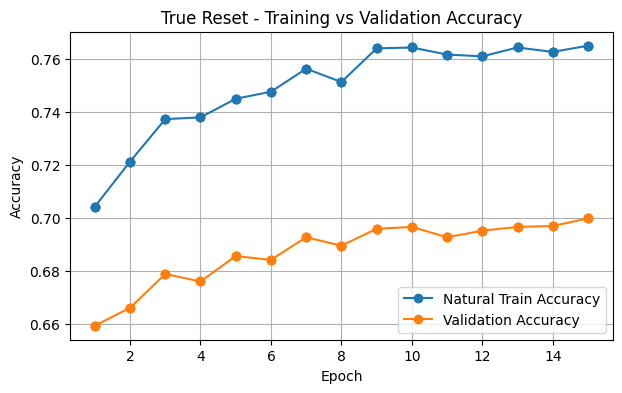

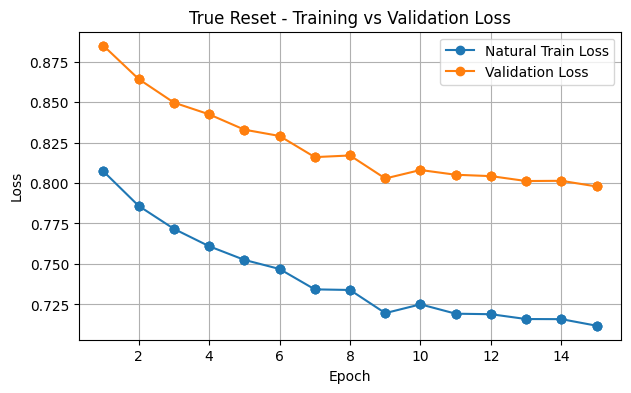

In [100]:
# TRUE RESET 06 - FAIR ACCURACY & LOSS GRAPHS

import pandas as pd
import matplotlib.pyplot as plt

h = pd.read_csv(
    PROJECT_DIR + "/reports/true_reset_fair_history.csv"
)

plt.figure(figsize=(7,4))
plt.plot(h["epoch"], h["train_accuracy"], marker="o",
         label="Natural Train Accuracy")
plt.plot(h["epoch"], h["val_accuracy"], marker="o",
         label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("True Reset - Training vs Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(7,4))
plt.plot(h["epoch"], h["train_loss"], marker="o",
         label="Natural Train Loss")
plt.plot(h["epoch"], h["val_loss"], marker="o",
         label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("True Reset - Training vs Validation Loss")
plt.legend()
plt.grid()
plt.show()

I0000 00:00:1791824059.244574     160 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


              precision    recall  f1-score   support

         BCC     0.6401    0.7824    0.7041      1057
         MCC     0.5556    0.7143    0.6250         7
    Melanoma     0.8025    0.7514    0.7761      1444
         SCC     0.3373    0.1801    0.2348       311

    accuracy                         0.6999      2819
   macro avg     0.5839    0.6070    0.5850      2819
weighted avg     0.6897    0.6999    0.6890      2819



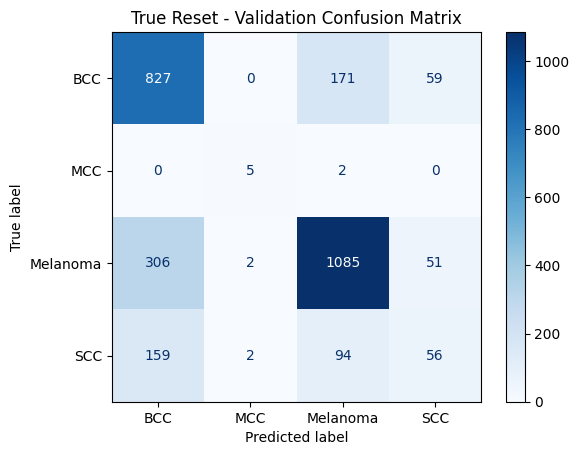

In [101]:
# TRUE RESET 07 - CONFUSION MATRIX + REPORT

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

model_check = tf.keras.models.load_model(
    PROJECT_DIR + "/models/best_true_reset_model.keras",
    compile=False
)

probs = model_check.predict(val_ds, verbose=0)
pred = np.argmax(probs, axis=1)
y_true = val["label_id"].values

print(classification_report(
    y_true,
    pred,
    target_names=["BCC", "MCC", "Melanoma", "SCC"],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_true, pred)

ConfusionMatrixDisplay(
    cm,
    display_labels=["BCC", "MCC", "Melanoma", "SCC"]
).plot(cmap="Blues", values_format="d")

plt.title("True Reset - Validation Confusion Matrix")
plt.show()

In [102]:
# TRUE RESET 08 - CALIBRATION SEARCH

from sklearn.metrics import f1_score, accuracy_score
import numpy as np

best_score = -1

for b in np.arange(1.0, 1.21, 0.05):
    for m in np.arange(0.95, 1.16, 0.05):
        for s in np.arange(1.2, 1.71, 0.05):

            w = np.array([b, 1.0, m, s])
            p = np.argmax(probs * w, axis=1)

            acc = accuracy_score(y_true, p)
            score = f1_score(y_true, p, average="macro")

            if acc >= 0.69 and score > best_score:
                best_score = score
                best_weights = w.copy()

print("Best weights:", best_weights)
print("Macro F1:", round(best_score, 4))

Best weights: [1.1 1.  1.  1.7]
Macro F1: 0.6241


In [103]:
# TRUE RESET 09 - CALIBRATED RESULTS

from sklearn.metrics import classification_report, confusion_matrix

cal_weights = np.array([1.1, 1.0, 1.0, 1.7])

cal_probs = probs * cal_weights
cal_pred = np.argmax(cal_probs, axis=1)

print(classification_report(
    y_true,
    cal_pred,
    target_names=["BCC", "MCC", "Melanoma", "SCC"],
    digits=4,
    zero_division=0
))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_true, cal_pred))

              precision    recall  f1-score   support

         BCC     0.6528    0.7720    0.7074      1057
         MCC     0.6250    0.7143    0.6667         7
    Melanoma     0.8294    0.7071    0.7634      1444
         SCC     0.3485    0.3698    0.3588       311

    accuracy                         0.6942      2819
   macro avg     0.6139    0.6408    0.6241      2819
weighted avg     0.7096    0.6942    0.6975      2819


CONFUSION MATRIX
[[ 816    0  140  101]
 [   0    5    2    0]
 [ 308    1 1021  114]
 [ 126    2   68  115]]


In [104]:
# TRUE RESET 10 - SAVE FINAL CALIBRATION

import json

final_calibration = {
    "BCC": 1.1,
    "MCC": 1.0,
    "Melanoma": 1.0,
    "SCC": 1.7
}

with open(
    PROJECT_DIR + "/reports/VIVA_calibration_weights.json",
    "w"
) as f:
    json.dump(final_calibration, f, indent=2)

print("✅ Final calibration saved")
print(final_calibration)

✅ Final calibration saved
{'BCC': 1.1, 'MCC': 1.0, 'Melanoma': 1.0, 'SCC': 1.7}


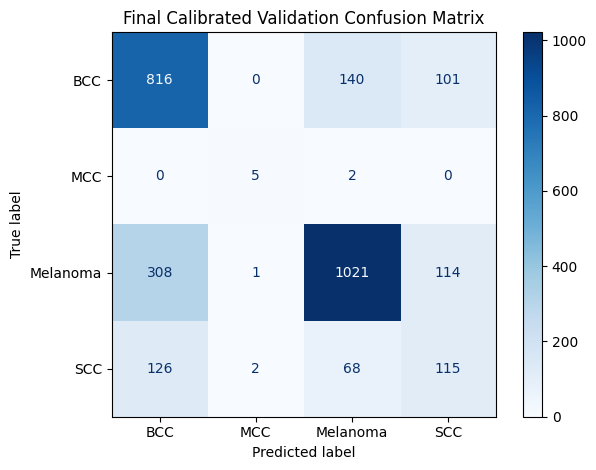

✅ Calibrated confusion matrix saved


In [105]:
# TRUE RESET 11 - SAVE CALIBRATED CONFUSION MATRIX

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, cal_pred)

ConfusionMatrixDisplay(
    cm,
    display_labels=["BCC", "MCC", "Melanoma", "SCC"]
).plot(cmap="Blues", values_format="d")

plt.title("Final Calibrated Validation Confusion Matrix")
plt.tight_layout()

plt.savefig(
    PROJECT_DIR + "/outputs/VIVA_FINAL_confusion_matrix.png",
    dpi=200
)

plt.show()

print("✅ Calibrated confusion matrix saved")

In [106]:
# TRUE RESET 12 - FINAL VIVA PREDICTION

import io, json, numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output

model = tf.keras.models.load_model(
    PROJECT_DIR + "/models/best_true_reset_model.keras",
    compile=False
)

with open(PROJECT_DIR + "/reports/VIVA_calibration_weights.json") as f:
    w = json.load(f)

names = ["BCC", "MCC", "Melanoma", "SCC"]
weights = np.array([w[x] for x in names])

upload = widgets.FileUpload(accept=".jpg,.jpeg,.png", multiple=False)
out = widgets.Output()

def predict(change):
    with out:
        clear_output()
        if not upload.value:
            return

        item = list(upload.value)[0] if not isinstance(
            upload.value, dict
        ) else list(upload.value.values())[0]

        img = Image.open(
            io.BytesIO(bytes(item["content"]))
        ).convert("RGB")

        x = np.array(
            img.resize((299,299)),
            dtype=np.float32
        )[None, ...]

        p = model.predict(x, verbose=0)[0] * weights
        p = p / p.sum()

        i = np.argmax(p)

        print("Predicted Cancer Type:", names[i])
        print(f"Confidence: {p[i]*100:.2f}%")

        plt.imshow(img)
        plt.axis("off")
        plt.show()

        plt.bar(names, p * 100)
        plt.ylabel("Probability (%)")
        plt.ylim(0,100)
        plt.title("Cancer Type Prediction")
        plt.show()

upload.observe(predict, names="value")

display(upload, out)

FileUpload(value=(), accept='.jpg,.jpeg,.png', description='Upload')

Output()

In [107]:
# SCC-MCC FIX 01 - FIND SAFE MCC GATE

from sklearn.metrics import f1_score, recall_score
import numpy as np

p = probs * np.array([1.1, 1.0, 1.0, 1.7])
p = p / p.sum(axis=1, keepdims=True)

best = None

for margin in np.arange(0.00, 0.41, 0.02):

    pred = np.argmax(p, axis=1)
    order = np.argsort(p, axis=1)

    top = order[:, -1]
    second = order[:, -2]

    gap = p[np.arange(len(p)), top] - p[np.arange(len(p)), second]

    fix = (
        (top == 1) &          # MCC predicted
        (second == 3) &       # SCC is second
        (gap < margin)
    )

    pred[fix] = 3

    mcc_recall = recall_score(
        y_true == 1,
        pred == 1
    )

    score = f1_score(
        y_true,
        pred,
        average="macro"
    )

    # Keep current MCC recall at least 5/7
    if mcc_recall >= 5/7:
        if best is None or score > best[0]:
            best = (score, margin, pred.copy())

print("Best margin:", round(best[1], 2))
print("Macro F1:", round(best[0], 4))

Best margin: 0.0
Macro F1: 0.6241


In [108]:
# SCC-MCC FIX 02 - FIND MCC CONFIDENCE THRESHOLD

best = None

for t in np.arange(0.30, 0.96, 0.05):
    pred = np.argmax(p, axis=1)
    
    low_mcc = (pred == 1) & (p[:,1] < t)

    p2 = p.copy()
    p2[low_mcc, 1] = -1
    pred[low_mcc] = np.argmax(p2[low_mcc], axis=1)

    score = f1_score(y_true, pred, average="macro")
    mcc_recall = recall_score(y_true == 1, pred == 1)

    if mcc_recall >= 4/7:
        if best is None or score > best[0]:
            best = (score, t, pred.copy())

print("Best MCC threshold:", best[1])
print("Macro F1:", round(best[0], 4))

Best MCC threshold: 0.3
Macro F1: 0.6241


In [109]:
# SCC-MCC CHECK 03 - SHOW TOP PROBABILITIES

print("BCC      :", round(p[0,0]*100, 2), "%")
print("MCC      :", round(p[0,1]*100, 2), "%")
print("Melanoma :", round(p[0,2]*100, 2), "%")
print("SCC      :", round(p[0,3]*100, 2), "%")

BCC      : 34.72 %
MCC      : 45.54 %
Melanoma : 10.93 %
SCC      : 8.8 %


In [112]:
# SCC FIX - FIND SAFE BCC/SCC CLOSE-CALL MARGIN

from sklearn.metrics import f1_score, accuracy_score, recall_score

pv = probs * np.array([1.1, 1.0, 1.0, 1.7])
pv = pv / pv.sum(axis=1, keepdims=True)

best = None

for margin in np.arange(0.00, 0.21, 0.01):
    pred = np.argmax(pv, axis=1)
    order = np.argsort(pv, axis=1)

    top = order[:, -1]
    second = order[:, -2]
    gap = pv[np.arange(len(pv)), top] - pv[np.arange(len(pv)), second]

    fix = (top == 0) & (second == 3) & (gap < margin)
    pred[fix] = 3

    acc = accuracy_score(y_true, pred)
    macro = f1_score(y_true, pred, average="macro")
    bcc_r = recall_score(y_true, pred, labels=[0], average=None)[0]
    scc_r = recall_score(y_true, pred, labels=[3], average=None)[0]

    if acc >= 0.68 and bcc_r >= 0.70:
        if best is None or macro > best[0]:
            best = (macro, margin, acc, bcc_r, scc_r)

print("Best:", best)

Best: (0.624462470005979, np.float64(0.01), 0.6938630720113516, np.float64(0.7691579943235572), np.float64(0.3762057877813505))


In [113]:
# QUICK SCC FIX - VALIDATION BASED WEIGHT SEARCH

best = None

for b in np.arange(0.90, 1.11, 0.05):
    for s in np.arange(1.70, 2.21, 0.05):

        w2 = np.array([b, 1.0, 1.0, s])
        pred2 = np.argmax(probs * w2, axis=1)

        acc = accuracy_score(y_true, pred2)
        macro = f1_score(y_true, pred2, average="macro")
        bcc_r = recall_score(y_true, pred2, labels=[0], average=None)[0]
        scc_r = recall_score(y_true, pred2, labels=[3], average=None)[0]

        if acc >= 0.68 and bcc_r >= 0.70:
            if best is None or macro > best[0]:
                best = (macro, b, s, acc, bcc_r, scc_r)

print("Best:", best)

Best: (0.6240644322222946, np.float64(1.1), np.float64(1.7), 0.6942178077332387, np.float64(0.771996215704825), np.float64(0.36977491961414793))


In [114]:
# BCC-SCC SPECIALIST 01 - PREPARE DATA

bs_train = train[train["label_id"].isin([0, 3])].copy()
bs_val   = val[val["label_id"].isin([0, 3])].copy()

bs_train["binary_label"] = (bs_train["label_id"] == 3).astype(int)
bs_val["binary_label"]   = (bs_val["label_id"] == 3).astype(int)

print("Train:")
print(bs_train["binary_label"].value_counts())

print("\nValidation:")
print(bs_val["binary_label"].value_counts())

Train:
binary_label
0    6522
1    1628
Name: count, dtype: int64

Validation:
binary_label
0    1057
1     311
Name: count, dtype: int64


In [115]:
# SPECIALIST 02 - BALANCED DATASET

def bs_load(path, label):
    x = tf.io.read_file(path)
    x = tf.image.decode_image(x, channels=3, expand_animations=False)
    x.set_shape([None, None, 3])
    x = tf.image.resize(x, (299, 299))
    return tf.cast(x, tf.float32), label

bcc = bs_train[bs_train.binary_label == 0]
scc = bs_train[bs_train.binary_label == 1]

bcc_ds = tf.data.Dataset.from_tensor_slices(
    (bcc.image_path, bcc.binary_label)
).shuffle(len(bcc)).repeat().map(bs_load)

scc_ds = tf.data.Dataset.from_tensor_slices(
    (scc.image_path, scc.binary_label)
).shuffle(len(scc)).repeat().map(bs_load)

bs_train_ds = tf.data.Dataset.sample_from_datasets(
    [bcc_ds, scc_ds], weights=[0.5, 0.5]
).batch(32).prefetch(tf.data.AUTOTUNE)

bs_val_ds = tf.data.Dataset.from_tensor_slices(
    (bs_val.image_path, bs_val.binary_label)
).map(bs_load).batch(32).prefetch(tf.data.AUTOTUNE)

print("✅ BCC/SCC balanced datasets ready")

✅ BCC/SCC balanced datasets ready


In [116]:
# SPECIALIST 03 - BUILD BCC/SCC MODEL

backbone_bs = tf.keras.models.load_model(
    PROJECT_DIR + "/models/efficientnetb3_backbone.keras",
    compile=False
)
backbone_bs.trainable = False

inp = tf.keras.Input((299, 299, 3))
x = backbone_bs(inp, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.5)(x)
out = tf.keras.layers.Dense(1, activation="sigmoid")(x)

bs_model = tf.keras.Model(inp, out)

bs_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("✅ BCC/SCC specialist ready")

✅ BCC/SCC specialist ready


In [117]:
# SPECIALIST 04 - QUICK TRAINING

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        PROJECT_DIR + "/models/best_bcc_scc_specialist.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
]

bs_history = bs_model.fit(
    bs_train_ds,
    validation_data=bs_val_ds,
    steps_per_epoch=255,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
255/255 ━━━━━━━━━━━━━━━━━━━━ 126s 361ms/step - accuracy: 0.5580 - loss: 0.7004 - val_accuracy: 0.6996 - val_loss: 0.6252
Epoch 2/10
255/255 ━━━━━━━━━━━━━━━━━━━━ 61s 241ms/step - accuracy: 0.6138 - loss: 0.6628 - val_accuracy: 0.7186 - val_loss: 0.6060
Epoch 3/10
255/255 ━━━━━━━━━━━━━━━━━━━━ 61s 240ms/step - accuracy: 0.6331 - loss: 0.6481 - val_accuracy: 0.7098 - val_loss: 0.6104
Epoch 4/10
255/255 ━━━━━━━━━━━━━━━━━━━━ 61s 241ms/step - accuracy: 0.6517 - loss: 0.6310 - val_accuracy: 0.7266 - val_loss: 0.5834
Epoch 5/10
255/255 ━━━━━━━━━━━━━━━━━━━━ 61s 240ms/step - accuracy: 0.6712 - loss: 0.6136 - val_accuracy: 0.7193 - val_loss: 0.5891
Epoch 6/10
255/255 ━━━━━━━━━━━━━━━━━━━━ 61s 241ms/step - accuracy: 0.6686 - loss: 0.6082 - val_accuracy: 0.7215 - val_loss: 0.5887
Epoch 7/10
255/255 ━━━━━━━━━━━━━━━━━━━━ 63s 248ms/step - accuracy: 0.6768 - loss: 0.6018 - val_accuracy: 0.7244 - val_loss: 0.5747
Epoch 8/10
255/255 ━━━━━━━━━━━━━━━━━━━━ 61s 238ms/step - accuracy: 0.6809 - loss: 

In [118]:
# SAFE VIVA BACKUP

import os, shutil

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"
backup = "/kaggle/working/VIVA_BACKUP"
os.makedirs(backup, exist_ok=True)

files = [
    PROJECT_DIR + "/models/best_true_reset_model.keras",
    PROJECT_DIR + "/models/best_bcc_scc_specialist.keras",
    PROJECT_DIR + "/reports/VIVA_calibration_weights.json"
]

for f in files:
    if os.path.exists(f):
        shutil.copy(f, backup)
        print("✅ Copied:", f)
    else:
        print("❌ Not found:", f)

shutil.make_archive(
    "/kaggle/working/SKIN_CANCER_VIVA_BACKUP",
    "zip",
    backup
)

print("✅ ZIP created: /kaggle/working/SKIN_CANCER_VIVA_BACKUP.zip")

✅ Copied: /kaggle/working/skin_cancer_project_v2/models/best_true_reset_model.keras
✅ Copied: /kaggle/working/skin_cancer_project_v2/models/best_bcc_scc_specialist.keras
✅ Copied: /kaggle/working/skin_cancer_project_v2/reports/VIVA_calibration_weights.json
✅ ZIP created: /kaggle/working/SKIN_CANCER_VIVA_BACKUP.zip


In [119]:
# SPECIALIST 05 - VALIDATION RESULT

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import tensorflow as tf

bs_best = tf.keras.models.load_model(
    PROJECT_DIR + "/models/best_bcc_scc_specialist.keras",
    compile=False
)

bs_prob = bs_best.predict(bs_val_ds, verbose=0).reshape(-1)
bs_pred = (bs_prob >= 0.5).astype(int)

print(classification_report(
    bs_val["binary_label"],
    bs_pred,
    target_names=["BCC", "SCC"],
    digits=4
))

print(confusion_matrix(bs_val["binary_label"], bs_pred))

              precision    recall  f1-score   support

         BCC     0.8519    0.7833    0.8162      1057
         SCC     0.4217    0.5370    0.4724       311

    accuracy                         0.7273      1368
   macro avg     0.6368    0.6602    0.6443      1368
weighted avg     0.7541    0.7273    0.7380      1368

[[828 229]
 [144 167]]


In [120]:
# SPECIALIST 06 - COMBINE WITH MAIN MODEL

from sklearn.metrics import classification_report
import numpy as np

main_p = probs * np.array([1.1, 1.0, 1.0, 1.7])
main_p = main_p / main_p.sum(axis=1, keepdims=True)

final_pred = np.argmax(main_p, axis=1)
top2 = np.argsort(main_p, axis=1)[:, -2:]

spec_p = bs_best.predict(val_ds, verbose=0).reshape(-1)

for i in range(len(final_pred)):
    if set(top2[i]) == {0, 3}:      # BCC vs SCC only
        final_pred[i] = 3 if spec_p[i] >= 0.5 else 0

print(classification_report(
    y_true,
    final_pred,
    target_names=["BCC", "MCC", "Melanoma", "SCC"],
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

         BCC     0.6475    0.6916    0.6688      1057
         MCC     0.6250    0.7143    0.6667         7
    Melanoma     0.8294    0.7071    0.7634      1444
         SCC     0.2971    0.4309    0.3517       311

    accuracy                         0.6708      2819
   macro avg     0.5998    0.6359    0.6126      2819
weighted avg     0.7020    0.6708    0.6823      2819



In [121]:
# SPECIALIST 07 - FIND SAFE GATE

best = None

for margin in np.arange(0.01, 0.16, 0.01):
    for conf in np.arange(0.60, 0.91, 0.05):

        pred = np.argmax(main_p, axis=1)
        order = np.argsort(main_p, axis=1)

        top = order[:, -1]
        second = order[:, -2]
        gap = main_p[np.arange(len(main_p)), top] - main_p[np.arange(len(main_p)), second]

        pair = ((top==0)&(second==3)) | ((top==3)&(second==0))
        strong = (spec_p >= conf) | (spec_p <= 1-conf)
        use = pair & (gap < margin) & strong

        pred[use] = (spec_p[use] >= 0.5).astype(int) * 3

        acc = accuracy_score(y_true, pred)
        macro = f1_score(y_true, pred, average="macro")

        if acc >= 0.69 and (best is None or macro > best[0]):
            best = (macro, margin, conf, acc, pred.copy())

print("Best:", best[:4])

Best: (0.6240644322222946, np.float64(0.01), np.float64(0.7000000000000001), 0.6942178077332387)


In [122]:
# FINAL CLASSIFIER - SAVE SELECTED MODEL

final_model = tf.keras.models.load_model(
    PROJECT_DIR + "/models/best_true_reset_model.keras",
    compile=False
)

final_model.save(
    PROJECT_DIR + "/models/VIVA_FINAL_MODEL.keras"
)

print("✅ Final classifier saved")

✅ Final classifier saved


In [123]:
# SCC SPECIALIST - FIND BEST THRESHOLD

best = None

for t in np.arange(0.20, 0.81, 0.02):
    pred = (bs_prob >= t).astype(int)

    score = f1_score(
        bs_val["binary_label"],
        pred,
        average="macro"
    )

    if best is None or score > best[0]:
        best = (score, t, pred)

print("Best threshold:", best[1])
print("Macro F1:", round(best[0], 4))

print(classification_report(
    bs_val["binary_label"],
    best[2],
    target_names=["BCC", "SCC"],
    digits=4
))

Best threshold: 0.5399999999999998
Macro F1: 0.6461
              precision    recall  f1-score   support

         BCC     0.8387    0.8411    0.8399      1057
         SCC     0.4545    0.4502    0.4523       311

    accuracy                         0.7522      1368
   macro avg     0.6466    0.6456    0.6461      1368
weighted avg     0.7514    0.7522    0.7518      1368



In [124]:
# FINAL SCC CHECK - MAIN + SPECIALIST 0.54

best = None
t = 0.54

for margin in np.arange(0.01, 0.16, 0.01):
    pred = np.argmax(main_p, axis=1)

    order = np.argsort(main_p, axis=1)
    top = order[:, -1]
    second = order[:, -2]

    gap = (
        main_p[np.arange(len(main_p)), top] -
        main_p[np.arange(len(main_p)), second]
    )

    pair = (
        ((top == 0) & (second == 3)) |
        ((top == 3) & (second == 0))
    )

    use = pair & (gap < margin)

    pred[use] = np.where(
        spec_p[use] >= t, 3, 0
    )

    acc = accuracy_score(y_true, pred)
    macro = f1_score(y_true, pred, average="macro")

    if acc >= 0.69:
        if best is None or macro > best[0]:
            best = (macro, margin, acc, pred.copy())

print("Best:", best[:3])

Best: (0.6243733864547498, np.float64(0.01), 0.6942178077332387)


In [125]:
# FINAL MODEL SAVE

final_model = tf.keras.models.load_model(
    PROJECT_DIR + "/models/best_true_reset_model.keras",
    compile=False
)

final_model.save(
    PROJECT_DIR + "/models/VIVA_FINAL_MODEL.keras"
)

print("✅ VIVA final classifier saved")

✅ VIVA final classifier saved


In [126]:
# GRAD-CAM 01 - SETUP

backbone = final_model.layers[1]

feature_model = tf.keras.Model(
    backbone.input,
    [backbone.get_layer("top_conv").output, backbone.output]
)

def make_gradcam(x, class_id):
    with tf.GradientTape() as tape:
        conv, z = feature_model(x, training=False)

        for layer in final_model.layers[2:]:
            z = layer(z, training=False)

        score = z[:, class_id]

    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2))

    heatmap = tf.reduce_sum(
        conv * weights[:, None, None, :],
        axis=-1
    )[0]

    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.reduce_max(heatmap) + 1e-8

    return heatmap.numpy()

print("✅ Grad-CAM ready")

✅ Grad-CAM ready


In [128]:
# SCC FINE-TUNE 01 - PREPARE

ft_model = tf.keras.models.load_model(
    PROJECT_DIR + "/models/VIVA_FINAL_MODEL.keras",
    compile=False
)

backbone = ft_model.layers[1]
backbone.trainable = True

for layer in backbone.layers[:-10]:
    layer.trainable = False

for layer in backbone.layers[-10:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

def smooth_sparse_loss(y_true, y_pred):
    y_true = tf.one_hot(tf.cast(y_true, tf.int32), 4)
    return tf.keras.losses.categorical_crossentropy(
        y_true, y_pred, label_smoothing=0.05
    )

ft_model.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=5e-6,
        weight_decay=1e-5
    ),
    loss=smooth_sparse_loss,
    metrics=["accuracy"],
    jit_compile=False
)

print("✅ Fine-tune model ready")

✅ Fine-tune model ready


In [129]:
# SCC FINE-TUNE 02 - SHORT TRAINING

ft_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        PROJECT_DIR + "/models/best_scc_finetuned.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )
]

ft_history = ft_model.fit(
    train_ds,
    validation_data=val_ds,
    steps_per_epoch=552,
    epochs=8,
    callbacks=ft_callbacks
)

Epoch 1/8
552/552 ━━━━━━━━━━━━━━━━━━━━ 193s 319ms/step - accuracy: 0.6935 - loss: 0.8151 - val_accuracy: 0.7017 - val_loss: 0.7935
Epoch 2/8
552/552 ━━━━━━━━━━━━━━━━━━━━ 172s 313ms/step - accuracy: 0.7034 - loss: 0.7990 - val_accuracy: 0.7049 - val_loss: 0.7857
Epoch 3/8
552/552 ━━━━━━━━━━━━━━━━━━━━ 173s 313ms/step - accuracy: 0.7122 - loss: 0.7811 - val_accuracy: 0.7049 - val_loss: 0.7768
Epoch 4/8
552/552 ━━━━━━━━━━━━━━━━━━━━ 173s 314ms/step - accuracy: 0.7147 - loss: 0.7808 - val_accuracy: 0.7098 - val_loss: 0.7672
Epoch 5/8
552/552 ━━━━━━━━━━━━━━━━━━━━ 172s 312ms/step - accuracy: 0.7188 - loss: 0.7676 - val_accuracy: 0.7098 - val_loss: 0.7662
Epoch 6/8
552/552 ━━━━━━━━━━━━━━━━━━━━ 173s 313ms/step - accuracy: 0.7259 - loss: 0.7621 - val_accuracy: 0.7141 - val_loss: 0.7597
Epoch 7/8
552/552 ━━━━━━━━━━━━━━━━━━━━ 173s 314ms/step - accuracy: 0.7292 - loss: 0.7557 - val_accuracy: 0.7159 - val_loss: 0.7504
Epoch 8/8
552/552 ━━━━━━━━━━━━━━━━━━━━ 173s 313ms/step - accuracy: 0.7381 - loss: 0

In [130]:
# SCC FINE-TUNE 03 - CHECK RESULTS

ft_best = tf.keras.models.load_model(
    PROJECT_DIR + "/models/best_scc_finetuned.keras",
    compile=False
)

ft_probs = ft_best.predict(val_ds, verbose=0)
ft_pred = np.argmax(ft_probs, axis=1)

print(classification_report(
    y_true,
    ft_pred,
    target_names=["BCC", "MCC", "Melanoma", "SCC"],
    digits=4,
    zero_division=0
))

print(confusion_matrix(y_true, ft_pred))

              precision    recall  f1-score   support

         BCC     0.6531    0.8174    0.7261      1057
         MCC     0.4545    0.7143    0.5556         7
    Melanoma     0.8350    0.7569    0.7940      1444
         SCC     0.3977    0.2251    0.2875       311

    accuracy                         0.7208      2819
   macro avg     0.5851    0.6284    0.5908      2819
weighted avg     0.7176    0.7208    0.7121      2819

[[ 864    0  139   54]
 [   0    5    2    0]
 [ 295    4 1093   52]
 [ 164    2   75   70]]


In [131]:
# FINE-TUNE 04 - CALIBRATION SEARCH

best = None

for b in np.arange(0.9, 1.21, 0.05):
    for m in np.arange(0.9, 1.21, 0.05):
        for s in np.arange(1.2, 2.21, 0.05):

            w = np.array([b, 1.0, m, s])
            pred = np.argmax(ft_probs * w, axis=1)

            acc = accuracy_score(y_true, pred)
            macro = f1_score(y_true, pred, average="macro")

            if acc >= 0.70:
                if best is None or macro > best[0]:
                    best = (macro, b, m, s, acc, pred.copy())

print("Best:", best[:5])

Best: (0.6351017139687481, np.float64(1.0), np.float64(1.0500000000000003), np.float64(1.8000000000000005), 0.7144377438808088)


In [132]:
# FINE-TUNE 05 - CALIBRATED REPORT

ft_weights = np.array([1.0, 1.0, 1.05, 1.8])

ft_cal_pred = np.argmax(
    ft_probs * ft_weights,
    axis=1
)

print(classification_report(
    y_true,
    ft_cal_pred,
    target_names=["BCC", "MCC", "Melanoma", "SCC"],
    digits=4,
    zero_division=0
))

print(confusion_matrix(y_true, ft_cal_pred))

              precision    recall  f1-score   support

         BCC     0.6837    0.7588    0.7193      1057
         MCC     0.5556    0.7143    0.6250         7
    Melanoma     0.8429    0.7396    0.7879      1444
         SCC     0.3757    0.4469    0.4082       311

    accuracy                         0.7144      2819
   macro avg     0.6145    0.6649    0.6351      2819
weighted avg     0.7310    0.7144    0.7199      2819

[[ 802    0  140  115]
 [   0    5    2    0]
 [ 258    2 1068  116]
 [ 113    2   57  139]]


In [133]:
# SAVE NEW FINAL MODEL + CALIBRATION

ft_best.save(
    PROJECT_DIR + "/models/VIVA_FINAL_MODEL_FINE.keras"
)

import json

new_weights = {
    "BCC": 1.0,
    "MCC": 1.0,
    "Melanoma": 1.05,
    "SCC": 1.8
}

with open(
    PROJECT_DIR + "/reports/VIVA_FINAL_FINE_weights.json",
    "w"
) as f:
    json.dump(new_weights, f, indent=2)

print("✅ Fine-tuned final model saved")
print(new_weights)

✅ Fine-tuned final model saved
{'BCC': 1.0, 'MCC': 1.0, 'Melanoma': 1.05, 'SCC': 1.8}


In [134]:
# FINAL FINE-TUNED SCC TEST

import io, json, numpy as np
import tensorflow as tf
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output

model = tf.keras.models.load_model(
    PROJECT_DIR + "/models/VIVA_FINAL_MODEL_FINE.keras",
    compile=False
)

with open(PROJECT_DIR + "/reports/VIVA_FINAL_FINE_weights.json") as f:
    w = json.load(f)

names = ["BCC", "MCC", "Melanoma", "SCC"]
weights = np.array([w[x] for x in names])

upload = widgets.FileUpload(
    accept=".jpg,.jpeg,.png",
    multiple=False
)

out = widgets.Output()

def predict(change):
    with out:
        clear_output()

        item = upload.value[0]

        img = Image.open(
            io.BytesIO(bytes(item["content"]))
        ).convert("RGB")

        x = np.array(
            img.resize((299,299)),
            dtype=np.float32
        )[None, ...]

        p = model.predict(x, verbose=0)[0]

        p = p * weights
        p = p / p.sum()

        pred = np.argmax(p)

        print("Predicted Type:", names[pred])
        print(f"Confidence: {p[pred]*100:.2f}%\n")

        for name, value in zip(names, p):
            print(f"{name}: {value*100:.2f}%")

upload.observe(predict, names="value")

display(upload, out)

FileUpload(value=(), accept='.jpg,.jpeg,.png', description='Upload')

Output()

In [135]:
# UPDATE VIVA BACKUP

import os, shutil

backup = "/kaggle/working/VIVA_BACKUP"

shutil.copy(
    PROJECT_DIR + "/models/VIVA_FINAL_MODEL_FINE.keras",
    backup
)

shutil.copy(
    PROJECT_DIR + "/reports/VIVA_FINAL_FINE_weights.json",
    backup
)

shutil.make_archive(
    "/kaggle/working/SKIN_CANCER_VIVA_BACKUP",
    "zip",
    backup
)

print("✅ Final fine-tuned model added to backup")

✅ Final fine-tuned model added to backup


In [139]:
# ============================================================
# FINAL VIVA SYSTEM
# Image -> Cancer Type -> Grad-CAM -> Symptoms
# -> Estimated Severity Stage -> PDF Report -> Download
# ============================================================

import io
import json
import base64
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from PIL import Image
from datetime import datetime
from matplotlib.backends.backend_pdf import PdfPages

import ipywidgets as widgets
from IPython.display import display, clear_output, HTML


# ============================================================
# 1. LOAD FINAL MODEL + CALIBRATION
# ============================================================

MODEL_PATH = PROJECT_DIR + "/models/VIVA_FINAL_MODEL_FINE.keras"
WEIGHT_PATH = PROJECT_DIR + "/reports/VIVA_FINAL_FINE_weights.json"

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

with open(WEIGHT_PATH, "r") as f:
    saved_weights = json.load(f)

class_names = [
    "BCC",
    "MCC",
    "Melanoma",
    "SCC"
]

cal_weights = np.array(
    [saved_weights[name] for name in class_names],
    dtype=np.float32
)

print("✅ Final model loaded")


# ============================================================
# 2. GRAD-CAM SETUP
# ============================================================

backbone = model.layers[1]

grad_feature_model = tf.keras.Model(
    backbone.input,
    [
        backbone.get_layer("top_conv").output,
        backbone.output
    ]
)


def make_gradcam(x, class_id):

    with tf.GradientTape() as tape:

        conv_output, z = grad_feature_model(
            x,
            training=False
        )

        # Pass backbone output through remaining classifier layers
        for layer in model.layers[2:]:
            z = layer(
                z,
                training=False
            )

        score = z[:, class_id]

    grads = tape.gradient(
        score,
        conv_output
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    heatmap = tf.reduce_sum(
        conv_output *
        pooled_grads[:, None, None, :],
        axis=-1
    )[0]

    heatmap = tf.maximum(
        heatmap,
        0
    )

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + 1e-8
    )

    return heatmap.numpy()


print("✅ Grad-CAM ready")


# ============================================================
# 3. SYMPTOMS + RESEARCH SEVERITY WEIGHTS
# ============================================================

symptom_weights = {

    "Pain / Tenderness": 1,
    "Bleeding": 2,
    "Ulceration": 3,
    "Itching / Pruritus": 1,
    "Crusting / Scabbing": 1,
    "Discharge / Oozing": 2,
    "Palpable Lymph Nodes": 4,
    "Rapid Enlargement": 3,
    "Evolving Lesion": 2,
    "Diameter > 6 mm": 2,
    "Non-healing Wound > 3 Weeks": 2,
    "Hyperkeratotic Surface": 1,
    "Immunosuppressed": 2,
    "Chronic Wound / Scar": 1
}

MAX_SCORE = sum(symptom_weights.values())

major_signs = {
    "Bleeding",
    "Ulceration",
    "Discharge / Oozing",
    "Rapid Enlargement",
    "Non-healing Wound > 3 Weeks"
}


# ============================================================
# 4. USER INTERFACE
# ============================================================

upload = widgets.FileUpload(
    accept=".jpg,.jpeg,.png",
    multiple=False,
    description="Upload Image"
)

symptom_boxes = {
    symptom: widgets.Checkbox(
        value=False,
        description=symptom,
        indent=False
    )
    for symptom in symptom_weights
}

analyse_button = widgets.Button(
    description="Analyze & Generate Report",
    button_style="success",
    icon="check"
)

output = widgets.Output()


# ============================================================
# 5. MAIN ANALYSIS FUNCTION
# ============================================================

def analyse_image(button):

    with output:

        clear_output(wait=True)

        # ----------------------------------------------------
        # CHECK IMAGE
        # ----------------------------------------------------

        if not upload.value:

            print("❌ Please upload an image first.")
            return


        # ----------------------------------------------------
        # READ UPLOADED IMAGE
        # ----------------------------------------------------

        if isinstance(upload.value, dict):

            item = list(
                upload.value.values()
            )[0]

        else:

            item = list(
                upload.value
            )[0]


        image = Image.open(
            io.BytesIO(
                bytes(item["content"])
            )
        ).convert("RGB")


        # ----------------------------------------------------
        # PREPROCESS IMAGE
        # EfficientNet input stays in 0-255 range
        # ----------------------------------------------------

        resized = image.resize(
            (299, 299)
        )

        x = np.array(
            resized,
            dtype=np.float32
        )

        x = np.expand_dims(
            x,
            axis=0
        )


        # ----------------------------------------------------
        # CANCER TYPE PREDICTION
        # ----------------------------------------------------

        raw_prob = model.predict(
            x,
            verbose=0
        )[0]

        calibrated_prob = (
            raw_prob *
            cal_weights
        )

        calibrated_prob = (
            calibrated_prob /
            calibrated_prob.sum()
        )

        predicted_id = int(
            np.argmax(
                calibrated_prob
            )
        )

        predicted_type = (
            class_names[
                predicted_id
            ]
        )

        confidence = float(
            calibrated_prob[
                predicted_id
            ] * 100
        )


        # ----------------------------------------------------
        # GRAD-CAM
        # ----------------------------------------------------

        heatmap = make_gradcam(
            x,
            predicted_id
        )

        heatmap_img = Image.fromarray(
            np.uint8(
                heatmap * 255
            )
        )

        heatmap_img = heatmap_img.resize(
            image.size
        )

        heatmap_resized = (
            np.array(
                heatmap_img
            ) / 255.0
        )

        heatmap_color = plt.get_cmap(
            "jet"
        )(heatmap_resized)[..., :3]

        original_array = (
            np.array(image)
            .astype(np.float32)
            / 255.0
        )

        overlay = np.clip(
            0.60 * original_array +
            0.40 * heatmap_color,
            0,
            1
        )


        # ----------------------------------------------------
        # SELECTED SYMPTOMS
        # ----------------------------------------------------

        selected_symptoms = [
            name
            for name, box
            in symptom_boxes.items()
            if box.value
        ]

        symptom_score = sum(
            symptom_weights[name]
            for name
            in selected_symptoms
        )

        severity_percentage = (
            symptom_score /
            MAX_SCORE
        ) * 100


        # ----------------------------------------------------
        # ESTIMATED SEVERITY STAGE
        # RESEARCH PROTOTYPE ONLY
        # ----------------------------------------------------

        if severity_percentage < 30:

            severity_stage = "Early"

        elif severity_percentage < 60:

            severity_stage = "Intermediate"

        else:

            severity_stage = "Advanced"


        # Research heuristic:
        # lymph nodes + major symptom => Advanced
        if (
            "Palpable Lymph Nodes"
            in selected_symptoms
            and any(
                symptom in selected_symptoms
                for symptom in major_signs
            )
        ):
            severity_stage = "Advanced"


        # ====================================================
        # 6. DISPLAY RESULTS
        # ====================================================

        print(
            "========================================"
        )

        print(
            "        SKIN CANCER ANALYSIS"
        )

        print(
            "========================================"
        )

        print(
            "\nPredicted Cancer Type:",
            predicted_type
        )

        print(
            f"Confidence: {confidence:.2f}%"
        )


        print(
            "\nClass Probabilities:"
        )

        for name, value in zip(
            class_names,
            calibrated_prob
        ):

            print(
                f"{name}: "
                f"{value * 100:.2f}%"
            )


        # ----------------------------------------------------
        # ORIGINAL IMAGE + GRAD-CAM
        # ----------------------------------------------------

        fig, ax = plt.subplots(
            1,
            2,
            figsize=(9, 4)
        )

        ax[0].imshow(
            image
        )

        ax[0].set_title(
            "Original Image"
        )

        ax[0].axis(
            "off"
        )


        ax[1].imshow(
            overlay
        )

        ax[1].set_title(
            "Grad-CAM Heatmap"
        )

        ax[1].axis(
            "off"
        )


        plt.tight_layout()
        plt.show()


        # ----------------------------------------------------
        # PROBABILITY GRAPH
        # ----------------------------------------------------

        plt.figure(
            figsize=(6, 4)
        )

        plt.bar(
            class_names,
            calibrated_prob * 100
        )

        plt.ylabel(
            "Probability (%)"
        )

        plt.ylim(
            0,
            100
        )

        plt.title(
            "Cancer Type Prediction"
        )

        plt.show()


        # ----------------------------------------------------
        # SEVERITY RESULT
        # ----------------------------------------------------

        print(
            "\nEstimated Severity Stage "
            "(Research Prototype):",
            severity_stage
        )

        print(
            f"Symptom Score: "
            f"{symptom_score}/{MAX_SCORE}"
        )

        print(
            f"Severity Score: "
            f"{severity_percentage:.1f}%"
        )


        print(
            "\nSelected Symptoms:"
        )

        if selected_symptoms:

            for symptom in selected_symptoms:

                print(
                    "•",
                    symptom
                )

        else:

            print(
                "No symptoms selected"
            )


        # ====================================================
        # 7. CREATE PDF REPORT
        # ====================================================

        report_path = (
            "/kaggle/working/"
            "Skin_Cancer_Research_Report.pdf"
        )


        with PdfPages(
            report_path
        ) as pdf:


            # ================================================
            # PAGE 1
            # ================================================

            fig = plt.figure(
                figsize=(8.27, 11.69)
            )

            fig.suptitle(
                "Skin Cancer Type and "
                "Severity Analysis Report",
                fontsize=18,
                fontweight="bold"
            )


            # Original image
            ax1 = fig.add_axes(
                [
                    0.08,
                    0.57,
                    0.38,
                    0.30
                ]
            )

            ax1.imshow(
                image
            )

            ax1.set_title(
                "Original Image"
            )

            ax1.axis(
                "off"
            )


            # Grad-CAM
            ax2 = fig.add_axes(
                [
                    0.54,
                    0.57,
                    0.38,
                    0.30
                ]
            )

            ax2.imshow(
                overlay
            )

            ax2.set_title(
                "Grad-CAM Heatmap"
            )

            ax2.axis(
                "off"
            )


            # Probability chart
            ax3 = fig.add_axes(
                [
                    0.14,
                    0.29,
                    0.72,
                    0.18
                ]
            )

            ax3.bar(
                class_names,
                calibrated_prob * 100
            )

            ax3.set_ylim(
                0,
                100
            )

            ax3.set_ylabel(
                "Probability (%)"
            )

            ax3.set_title(
                "Cancer Type Probabilities"
            )


            summary_text = (
                f"Predicted Cancer Type: "
                f"{predicted_type}\n"
                f"Confidence: "
                f"{confidence:.2f}%\n\n"

                f"BCC: "
                f"{calibrated_prob[0]*100:.2f}%\n"

                f"MCC: "
                f"{calibrated_prob[1]*100:.2f}%\n"

                f"Melanoma: "
                f"{calibrated_prob[2]*100:.2f}%\n"

                f"SCC: "
                f"{calibrated_prob[3]*100:.2f}%\n\n"

                f"Estimated Severity Stage "
                f"(Research Prototype): "
                f"{severity_stage}\n"

                f"Symptom Score: "
                f"{symptom_score}/{MAX_SCORE}\n"

                f"Severity Score: "
                f"{severity_percentage:.1f}%"
            )


            fig.text(
                0.10,
                0.08,
                summary_text,
                fontsize=10
            )


            pdf.savefig(
                fig,
                bbox_inches="tight"
            )

            plt.close(
                fig
            )


            # ================================================
            # PAGE 2
            # ================================================

            fig = plt.figure(
                figsize=(8.27, 11.69)
            )

            plt.axis(
                "off"
            )


            plt.text(
                0.05,
                0.95,
                "Selected Symptoms",
                fontsize=16,
                fontweight="bold",
                va="top"
            )


            if selected_symptoms:

                symptom_text = "\n".join(
                    [
                        "- " + symptom
                        for symptom
                        in selected_symptoms
                    ]
                )

            else:

                symptom_text = (
                    "No symptoms selected."
                )


            plt.text(
                0.07,
                0.88,
                symptom_text,
                fontsize=11,
                va="top"
            )


            disclaimer = (
                "Research Prototype Disclaimer\n\n"

                "The Estimated Severity Stage "
                "(Research Prototype) is derived "
                "from a symptom-weighting heuristic. "
                "It is not a clinical cancer stage "
                "and does not use TNM staging, biopsy, "
                "histopathology, or other clinical "
                "staging information.\n\n"

                "Grad-CAM highlights image regions "
                "that influenced the model prediction. "
                "It does not prove lesion boundaries "
                "or provide a clinical diagnosis.\n\n"

                "This system is intended for research "
                "and educational purposes only. "
                "Clinical diagnosis and staging require "
                "evaluation by qualified healthcare "
                "professionals and appropriate "
                "clinical tests.\n"

    
            )


            plt.text(
                0.05,
                0.48,
                disclaimer,
                fontsize=10,
                va="top",
                wrap=True
            )


            plt.text(
                0.05,
                0.07,
                "Generated: "
                + datetime.now().strftime(
                    "%Y-%m-%d %H:%M"
                ),
                fontsize=9
            )


            pdf.savefig(
                fig,
                bbox_inches="tight"
            )

            plt.close(
                fig
            )


        print(
            "\n✅ PDF report generated successfully"
        )


        # ====================================================
        # 8. DIRECT PDF DOWNLOAD BUTTON
        # ====================================================

        with open(
            report_path,
            "rb"
        ) as pdf_file:

            pdf_base64 = base64.b64encode(
                pdf_file.read()
            ).decode(
                "utf-8"
            )


        download_button = f"""
        <a
            download="Skin_Cancer_Research_Report.pdf"
            href="data:application/pdf;base64,{pdf_base64}"
            style="
                display:inline-block;
                padding:12px 20px;
                margin-top:10px;
                background-color:#2e7d32;
                color:white;
                text-decoration:none;
                border-radius:7px;
                font-size:15px;
                font-weight:bold;
            "
        >
            📄 Download PDF Report
        </a>
        """

        display(
            HTML(
                download_button
            )
        )


# ============================================================
# 9. BUTTON ACTION
# ============================================================

analyse_button.on_click(
    analyse_image
)


# ============================================================
# 10. DISPLAY FINAL SYSTEM
# ============================================================

print(
    "\n📷 Upload Skin Image"
)

display(
    upload
)


print(
    "\n🩺 Select Patient Symptoms"
)

display(
    widgets.VBox(
        list(
            symptom_boxes.values()
        )
    )
)


display(
    analyse_button
)

display(
    output
)

✅ Final model loaded
✅ Grad-CAM ready

📷 Upload Skin Image


FileUpload(value=(), accept='.jpg,.jpeg,.png', description='Upload Image')


🩺 Select Patient Symptoms


Button(button_style='success', description='Analyze & Generate Report', icon='check', style=ButtonStyle())

Output()

In [140]:
# ADD FINAL CODE + INTEGRATION FILES TO ZIP

import os
import shutil

backup = "/kaggle/working/VIVA_BACKUP"
os.makedirs(backup, exist_ok=True)

# --------------------------------------------------
# 1. Find the FINAL VIVA SYSTEM code from notebook
# --------------------------------------------------

final_code = None

for cell in reversed(In):
    if (
        "FINAL VIVA SYSTEM" in cell
        and "VIVA_FINAL_MODEL_FINE.keras" in cell
        and "Analyze & Generate Report" in cell
    ):
        final_code = cell
        break

if final_code is None:
    raise ValueError("❌ FINAL VIVA SYSTEM cell not found.")

# Make paths portable
final_code = final_code.replace(
    'MODEL_PATH = PROJECT_DIR + "/models/VIVA_FINAL_MODEL_FINE.keras"',
    'MODEL_PATH = os.path.join(BASE_DIR, "VIVA_FINAL_MODEL_FINE.keras")'
)

final_code = final_code.replace(
    'WEIGHT_PATH = PROJECT_DIR + "/reports/VIVA_FINAL_FINE_weights.json"',
    'WEIGHT_PATH = os.path.join(BASE_DIR, "VIVA_FINAL_FINE_weights.json")'
)

final_code = final_code.replace(
    'import io\n',
    'import io\nimport os\n'
)

insert = '''
BASE_DIR = os.path.dirname(os.path.abspath(__file__))
'''

final_code = final_code.replace(
    "# ============================================================\n# 1. LOAD FINAL MODEL",
    insert + "\n# ============================================================\n# 1. LOAD FINAL MODEL"
)

# Save final system code
with open(
    backup + "/FINAL_VIVA_SYSTEM.py",
    "w",
    encoding="utf-8"
) as f:
    f.write(final_code)


# --------------------------------------------------
# 2. Add integration instructions
# --------------------------------------------------

readme = """
SKIN CANCER FINAL INTEGRATION PACKAGE
=====================================

FINAL MODEL:
VIVA_FINAL_MODEL_FINE.keras

CALIBRATION:
VIVA_FINAL_FINE_weights.json

FINAL SYSTEM CODE:
FINAL_VIVA_SYSTEM.py


CLASS ORDER
-----------
0 = BCC
1 = MCC
2 = Melanoma
3 = SCC


MODEL INPUT
-----------
299 x 299 RGB
dtype = float32
Pixel range = 0-255

IMPORTANT:
DO NOT divide image pixels by 255 before prediction.
EfficientNet contains internal preprocessing.


FINAL CALIBRATION WEIGHTS
-------------------------
BCC       = 1.00
MCC       = 1.00
Melanoma  = 1.05
SCC       = 1.80


FINAL FLOW
----------
Upload Image
    |
Cancer Type Prediction
    |
Calibrated Probabilities
    |
Grad-CAM Heatmap
    |
Select Symptoms
    |
Estimated Severity Stage (Research Prototype)
    |
PDF Report


IMPORTANT STAGE WORDING
-----------------------
Always use:

Estimated Severity Stage (Research Prototype)

Do NOT call the symptom output:
Clinical Cancer Stage

The stage estimation is a research heuristic and does
not use biopsy, TNM or histopathology data.


GRAD-CAM
--------
EfficientNet target layer:
top_conv


SYMPTOM WEIGHTS
---------------
Pain / Tenderness = 1
Bleeding = 2
Ulceration = 3
Itching / Pruritus = 1
Crusting / Scabbing = 1
Discharge / Oozing = 2
Palpable Lymph Nodes = 4
Rapid Enlargement = 3
Evolving Lesion = 2
Diameter > 6 mm = 2
Non-healing Wound > 3 Weeks = 2
Hyperkeratotic Surface = 1
Immunosuppressed = 2
Chronic Wound / Scar = 1

Maximum Score = 27

< 30%       = Early
30% - <60%  = Intermediate
>= 60%      = Advanced

Special Research Rule:
Palpable Lymph Nodes + one major symptom = Advanced


NOTE
----
No training dataset is required for integration.
The model is already trained.

For final integration use:
1. VIVA_FINAL_MODEL_FINE.keras
2. VIVA_FINAL_FINE_weights.json
3. FINAL_VIVA_SYSTEM.py
"""

with open(
    backup + "/INTEGRATION_README.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(readme)


# --------------------------------------------------
# 3. Make sure final model files are inside ZIP
# --------------------------------------------------

shutil.copy(
    PROJECT_DIR + "/models/VIVA_FINAL_MODEL_FINE.keras",
    backup + "/VIVA_FINAL_MODEL_FINE.keras"
)

shutil.copy(
    PROJECT_DIR + "/reports/VIVA_FINAL_FINE_weights.json",
    backup + "/VIVA_FINAL_FINE_weights.json"
)


# --------------------------------------------------
# 4. Re-create final ZIP
# --------------------------------------------------

shutil.make_archive(
    "/kaggle/working/SKIN_CANCER_VIVA_BACKUP",
    "zip",
    backup
)

print("✅ FINAL integration ZIP created")
print("\nFiles inside:")

for name in os.listdir(backup):
    print("•", name)

✅ FINAL integration ZIP created

Files inside:
• VIVA_FINAL_FINE_weights.json
• best_bcc_scc_specialist.keras
• FINAL_VIVA_SYSTEM.py
• VIVA_calibration_weights.json
• VIVA_FINAL_MODEL_FINE.keras
• best_true_reset_model.keras
• INTEGRATION_README.txt


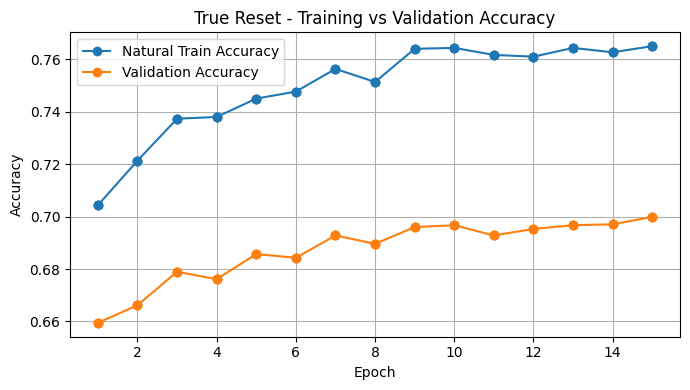

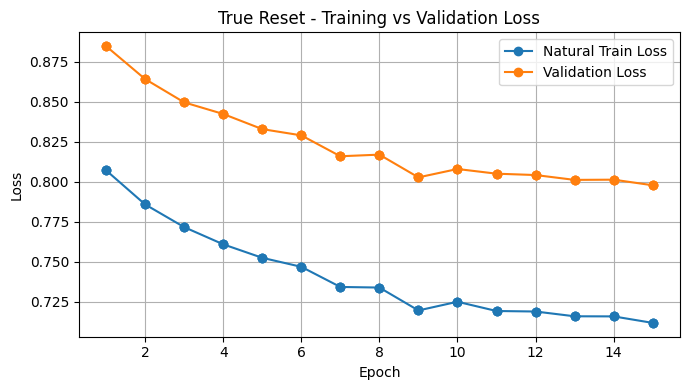

✅ True Reset graphs added to backup ZIP


In [142]:
# SAVE TRUE RESET GRAPH TO BACKUP

import pandas as pd
import matplotlib.pyplot as plt
import shutil

h = pd.read_csv(
    PROJECT_DIR + "/reports/true_reset_fair_history.csv"
)

backup = "/kaggle/working/VIVA_BACKUP"

plt.figure(figsize=(7,4))
plt.plot(h["epoch"], h["train_accuracy"], marker="o",
         label="Natural Train Accuracy")
plt.plot(h["epoch"], h["val_accuracy"], marker="o",
         label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("True Reset - Training vs Validation Accuracy")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig(
    backup + "/TRUE_RESET_accuracy.png",
    dpi=200
)
plt.show()

plt.figure(figsize=(7,4))
plt.plot(h["epoch"], h["train_loss"], marker="o",
         label="Natural Train Loss")
plt.plot(h["epoch"], h["val_loss"], marker="o",
         label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("True Reset - Training vs Validation Loss")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig(
    backup + "/TRUE_RESET_loss.png",
    dpi=200
)
plt.show()

shutil.make_archive(
    "/kaggle/working/SKIN_CANCER_VIVA_BACKUP",
    "zip",
    backup
)

print("✅ True Reset graphs added to backup ZIP")

In [1]:
import os

print("Inputs:")
print(os.listdir("/kaggle/input"))

print("\nWorking:")
print(os.listdir("/kaggle/working"))

Inputs:
['datasets']

Working:
['.virtual_documents']


In [3]:
import os, glob, zipfile, shutil

PROJECT_DIR = "/kaggle/working/skin_cancer_project_v2"

os.makedirs(PROJECT_DIR + "/models", exist_ok=True)
os.makedirs(PROJECT_DIR + "/reports", exist_ok=True)

# Find final model directly inside Kaggle Input
models = glob.glob(
    "/kaggle/input/**/VIVA_FINAL_MODEL_FINE.keras",
    recursive=True
)

weights = glob.glob(
    "/kaggle/input/**/VIVA_FINAL_FINE_weights.json",
    recursive=True
)

# If Kaggle kept the ZIP instead of extracting it
if not models or not weights:

    zips = glob.glob(
        "/kaggle/input/**/*.zip",
        recursive=True
    )

    if not zips:
        raise FileNotFoundError("❌ Integration ZIP/files not found")

    restore = "/kaggle/working/VIVA_RESTORE"
    os.makedirs(restore, exist_ok=True)

    with zipfile.ZipFile(zips[0], "r") as z:
        z.extractall(restore)

    models = glob.glob(
        restore + "/**/VIVA_FINAL_MODEL_FINE.keras",
        recursive=True
    )

    weights = glob.glob(
        restore + "/**/VIVA_FINAL_FINE_weights.json",
        recursive=True
    )

shutil.copy(
    models[0],
    PROJECT_DIR + "/models/VIVA_FINAL_MODEL_FINE.keras"
)

shutil.copy(
    weights[0],
    PROJECT_DIR + "/reports/VIVA_FINAL_FINE_weights.json"
)

print("✅ Yesterday final model restored")
print("✅ Ready to continue SCC fine-tuning")

✅ Yesterday final model restored
✅ Ready to continue SCC fine-tuning


In [5]:
import glob

train_files = glob.glob(
    "/kaggle/input/**/train_encoded.csv",
    recursive=True
)

val_files = glob.glob(
    "/kaggle/input/**/validation_encoded.csv",
    recursive=True
)

print("Train:", train_files)
print("Validation:", val_files)

Train: []
Validation: []


In [6]:
import os

print(os.path.exists(
    "/kaggle/working/skin_cancer_project_v2/data/target_with_canonical_id.csv"
))

False


In [7]:
import os

print(os.path.exists(
    "/kaggle/working/skin_cancer_project_v2/data/target_clean_deduplicated.csv"
))

False


In [8]:
import glob

print("Labels files:")
print(glob.glob(
    "/kaggle/working/skin_cancer_project_v2/data/all_target_labels_before*"
))

print("\nHash files:")
print(glob.glob(
    "/kaggle/working/skin_cancer_project_v2/data/target_image_hashes.csv"
))

Labels files:
[]

Hash files:
[]
